<a href="https://colab.research.google.com/github/ascot119-rgb/Alex-s-Projects/blob/main/Pytorch%20Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Epoch 500, Loss 2.927649
Epoch 1000, Loss 2.927646
Epoch 1500, Loss 2.927646
Epoch 2000, Loss 2.927646
Epoch 2500, Loss 2.927646
Epoch 3000, Loss 2.927646
Epoch 3500, Loss 2.927646
Epoch 4000, Loss 2.927646
Epoch 4500, Loss 2.927646
Epoch 5000, Loss 2.927646
Epoch 500, Loss nan
Epoch 1000, Loss nan
Epoch 1500, Loss nan
Epoch 2000, Loss nan
Epoch 2500, Loss nan
Epoch 3000, Loss nan
Epoch 3500, Loss nan
Epoch 4000, Loss nan
Epoch 4500, Loss nan
Epoch 5000, Loss nan


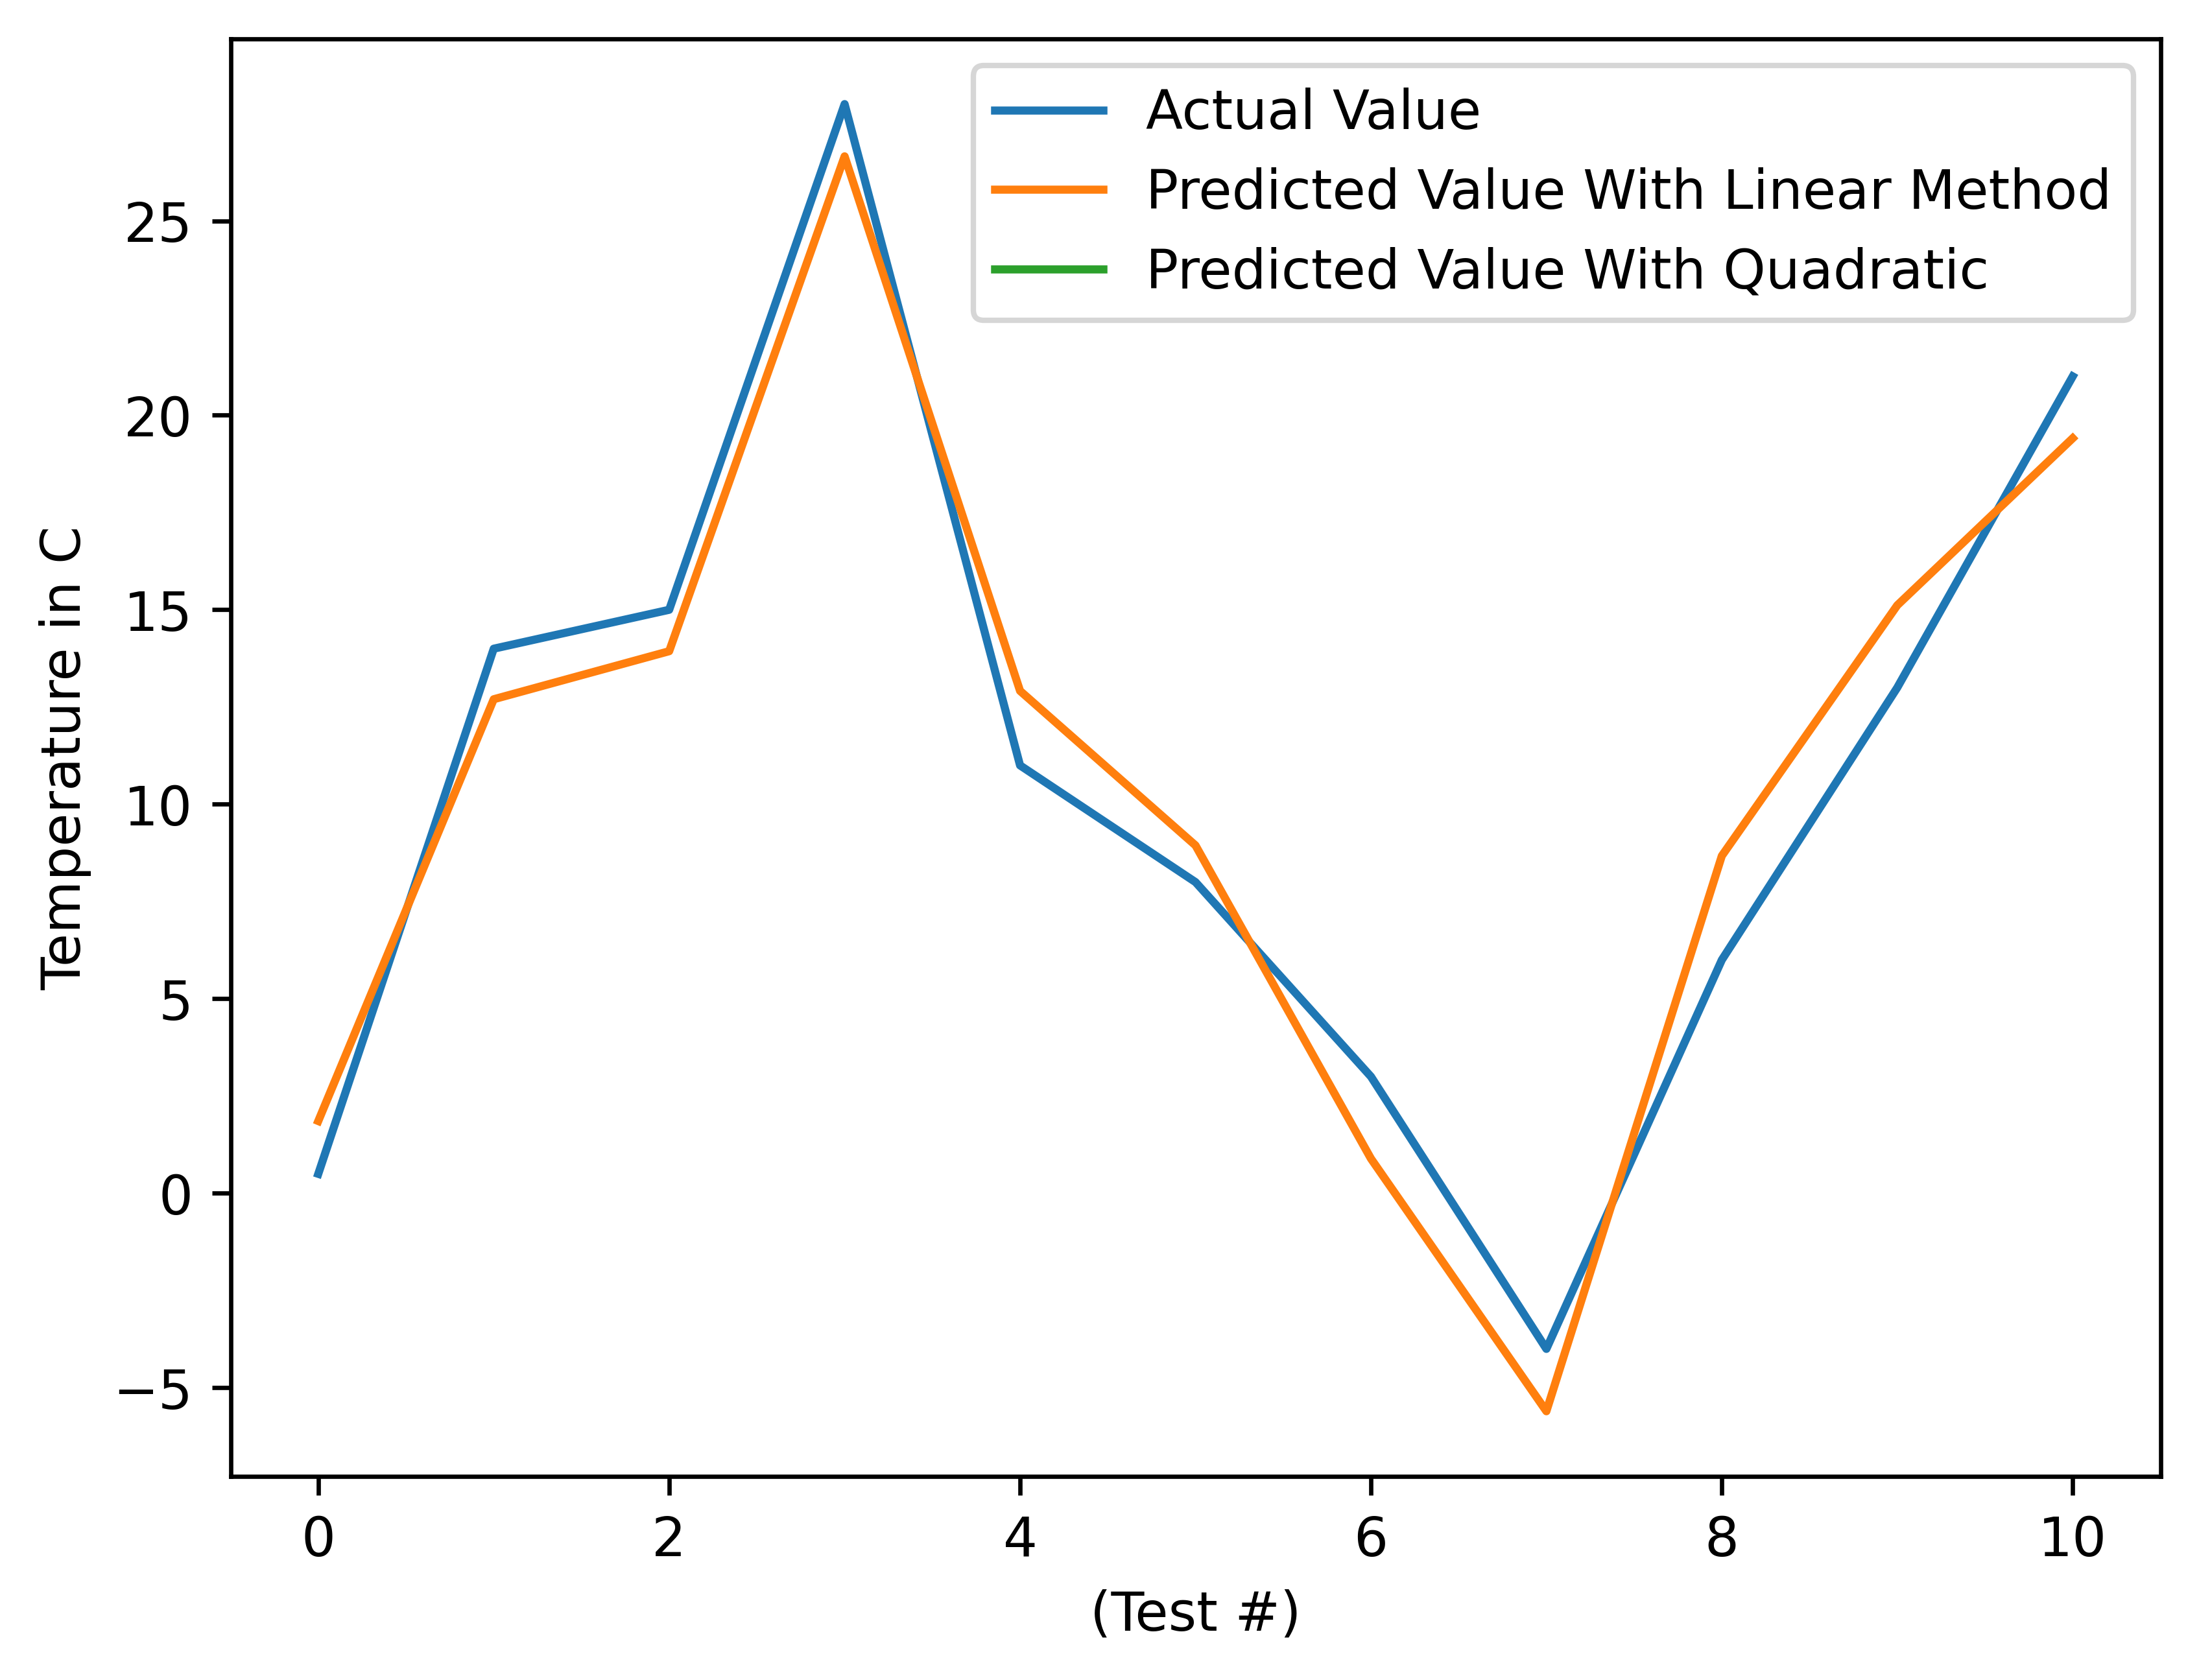

Epoch 500, Loss 9.223653
Epoch 1000, Loss 4.253827
Epoch 1500, Loss 3.206991
Epoch 2000, Loss 2.986487
Epoch 2500, Loss 2.940041
Epoch 3000, Loss 2.930258
Epoch 3500, Loss 2.928195
Epoch 4000, Loss 2.927763
Epoch 4500, Loss 2.927672
Epoch 5000, Loss 2.927650
Epoch 500, Loss 2.988865
Epoch 1000, Loss 2.833783
Epoch 1500, Loss 2.705555
Epoch 2000, Loss 2.599453
Epoch 2500, Loss 2.511661
Epoch 3000, Loss 2.439018
Epoch 3500, Loss 2.378914
Epoch 4000, Loss 2.329181
Epoch 4500, Loss 2.288030
Epoch 5000, Loss 2.253980


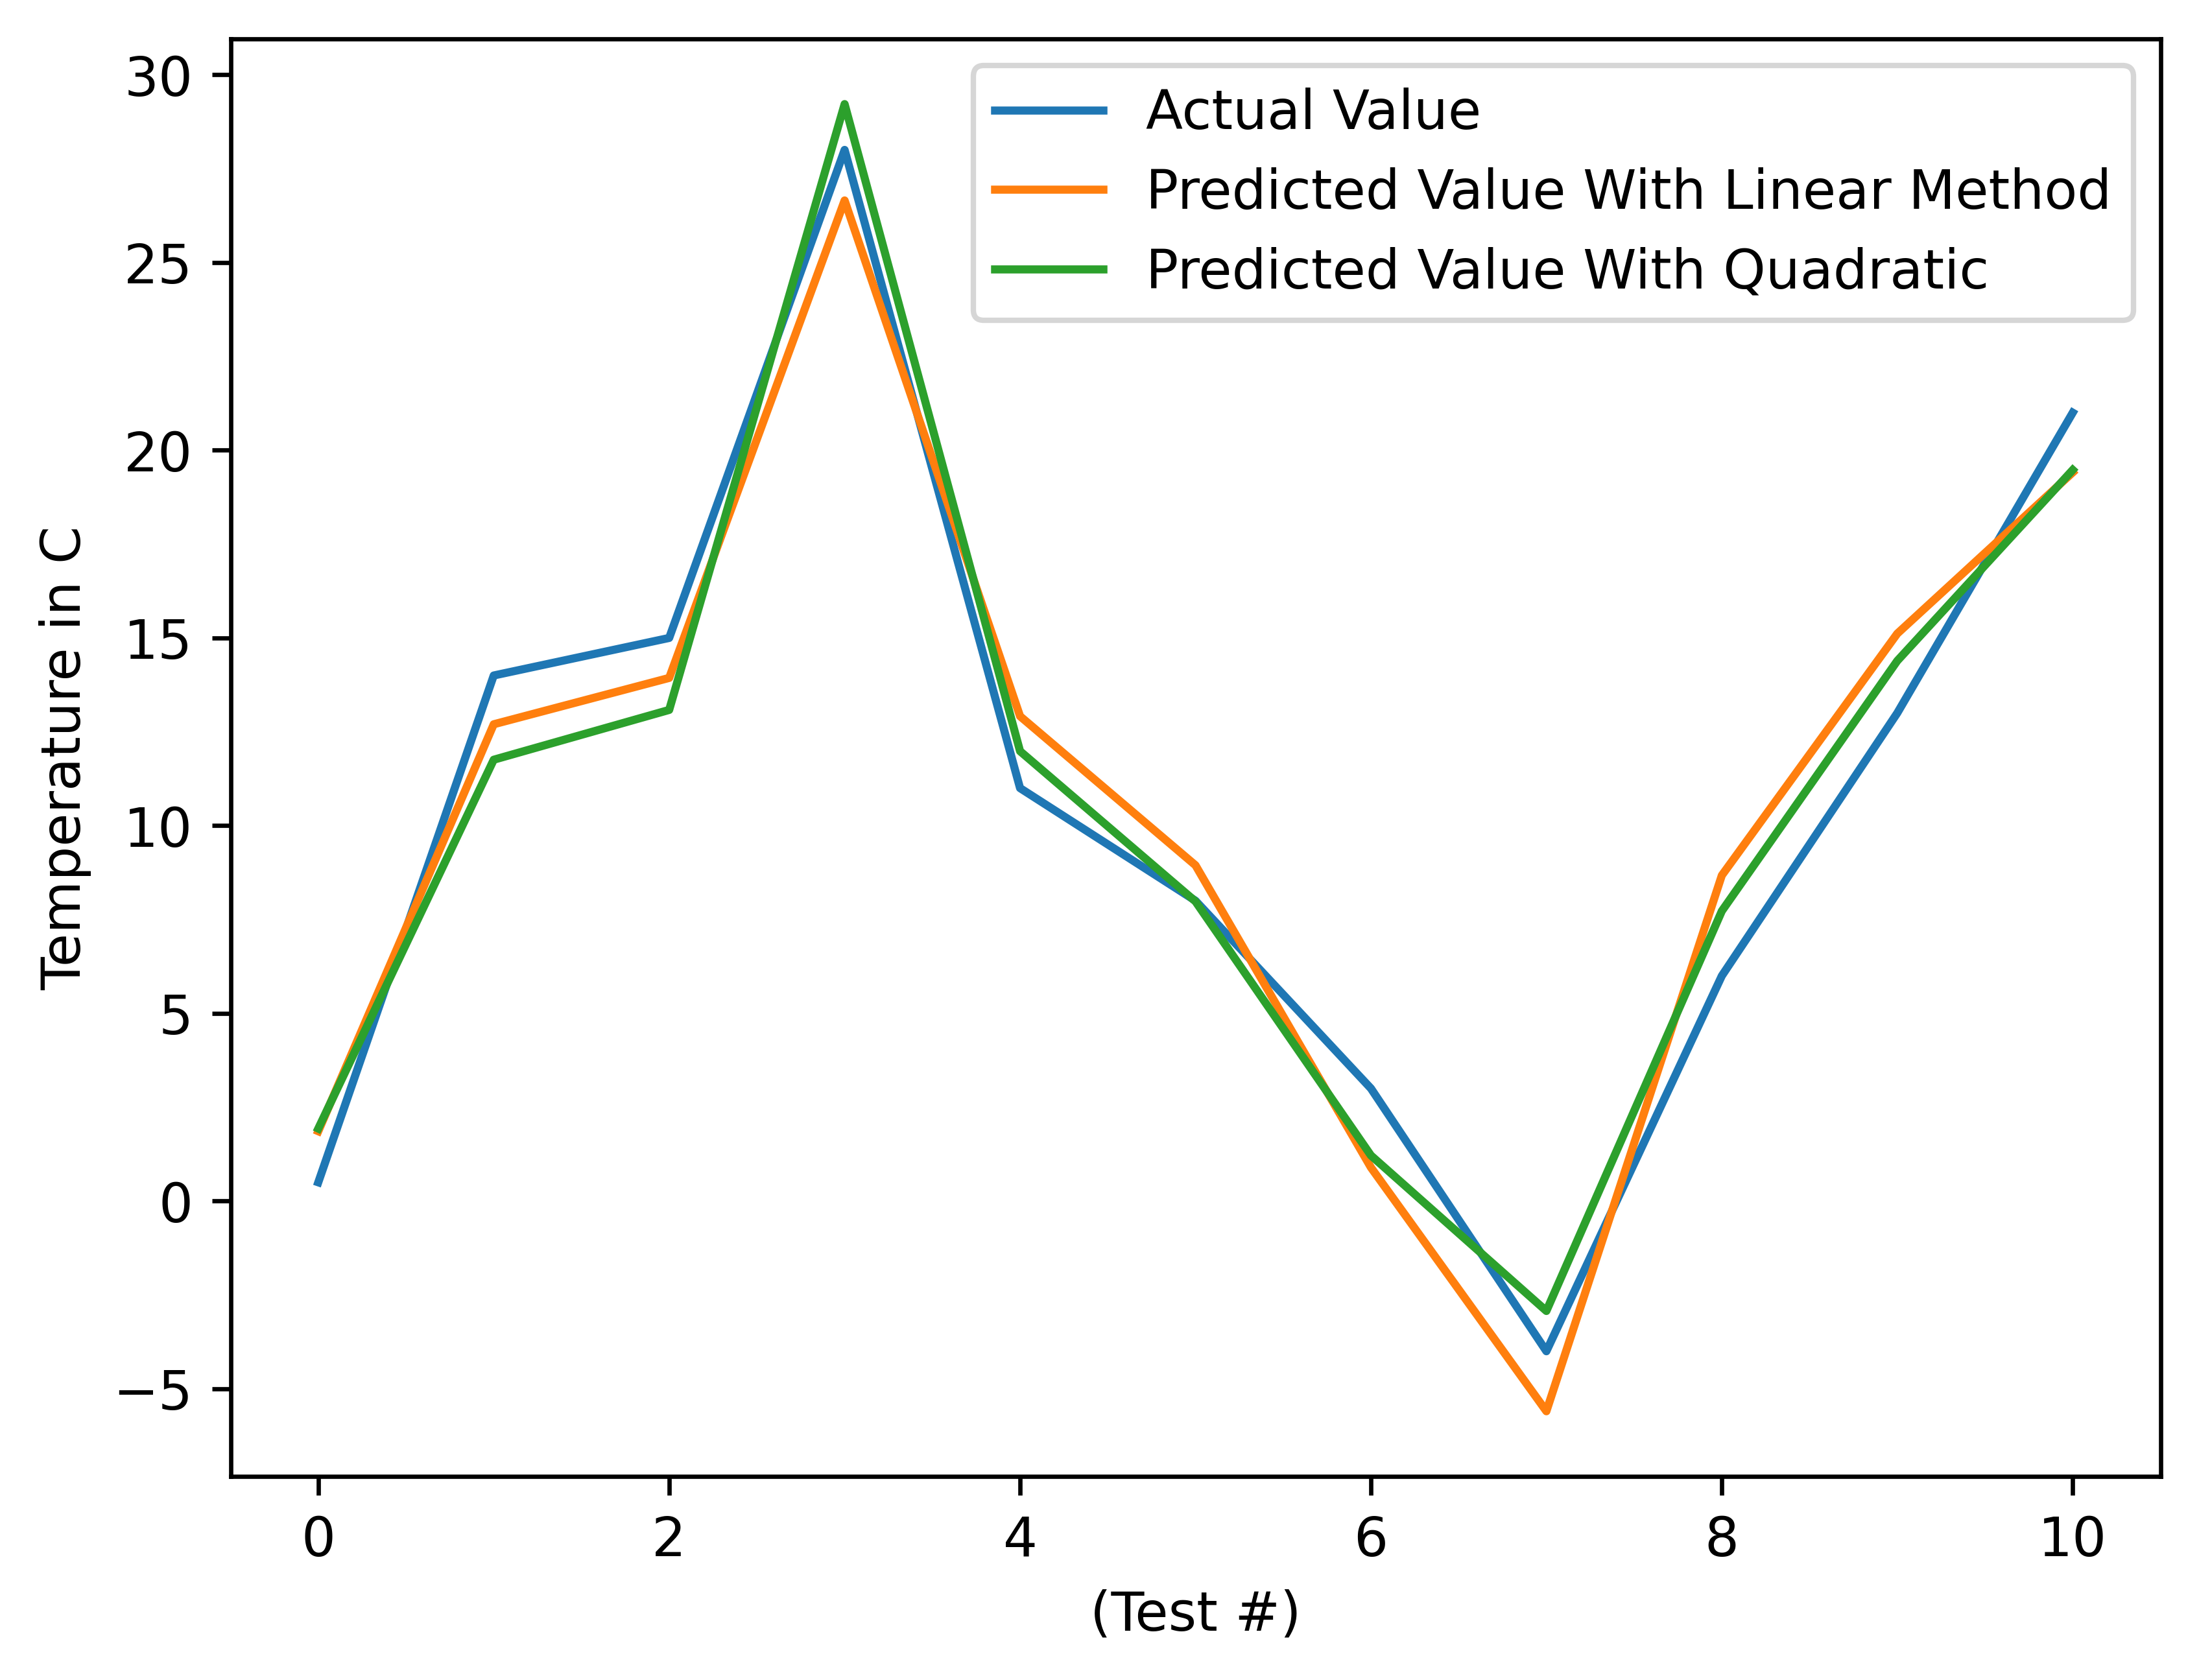

Epoch 500, Loss 28.437639
Epoch 1000, Loss 24.760548
Epoch 1500, Loss 21.613495
Epoch 2000, Loss 18.920061
Epoch 2500, Loss 16.614855
Epoch 3000, Loss 14.641940
Epoch 3500, Loss 12.953406
Epoch 4000, Loss 11.508268
Epoch 4500, Loss 10.271435
Epoch 5000, Loss 9.212875
Epoch 500, Loss 5.796658
Epoch 1000, Loss 3.996853
Epoch 1500, Loss 3.396740
Epoch 2000, Loss 3.188167
Epoch 2500, Loss 3.107539
Epoch 3000, Loss 3.068878
Epoch 3500, Loss 3.044140
Epoch 4000, Loss 3.024165
Epoch 4500, Loss 3.005973
Epoch 5000, Loss 2.988577


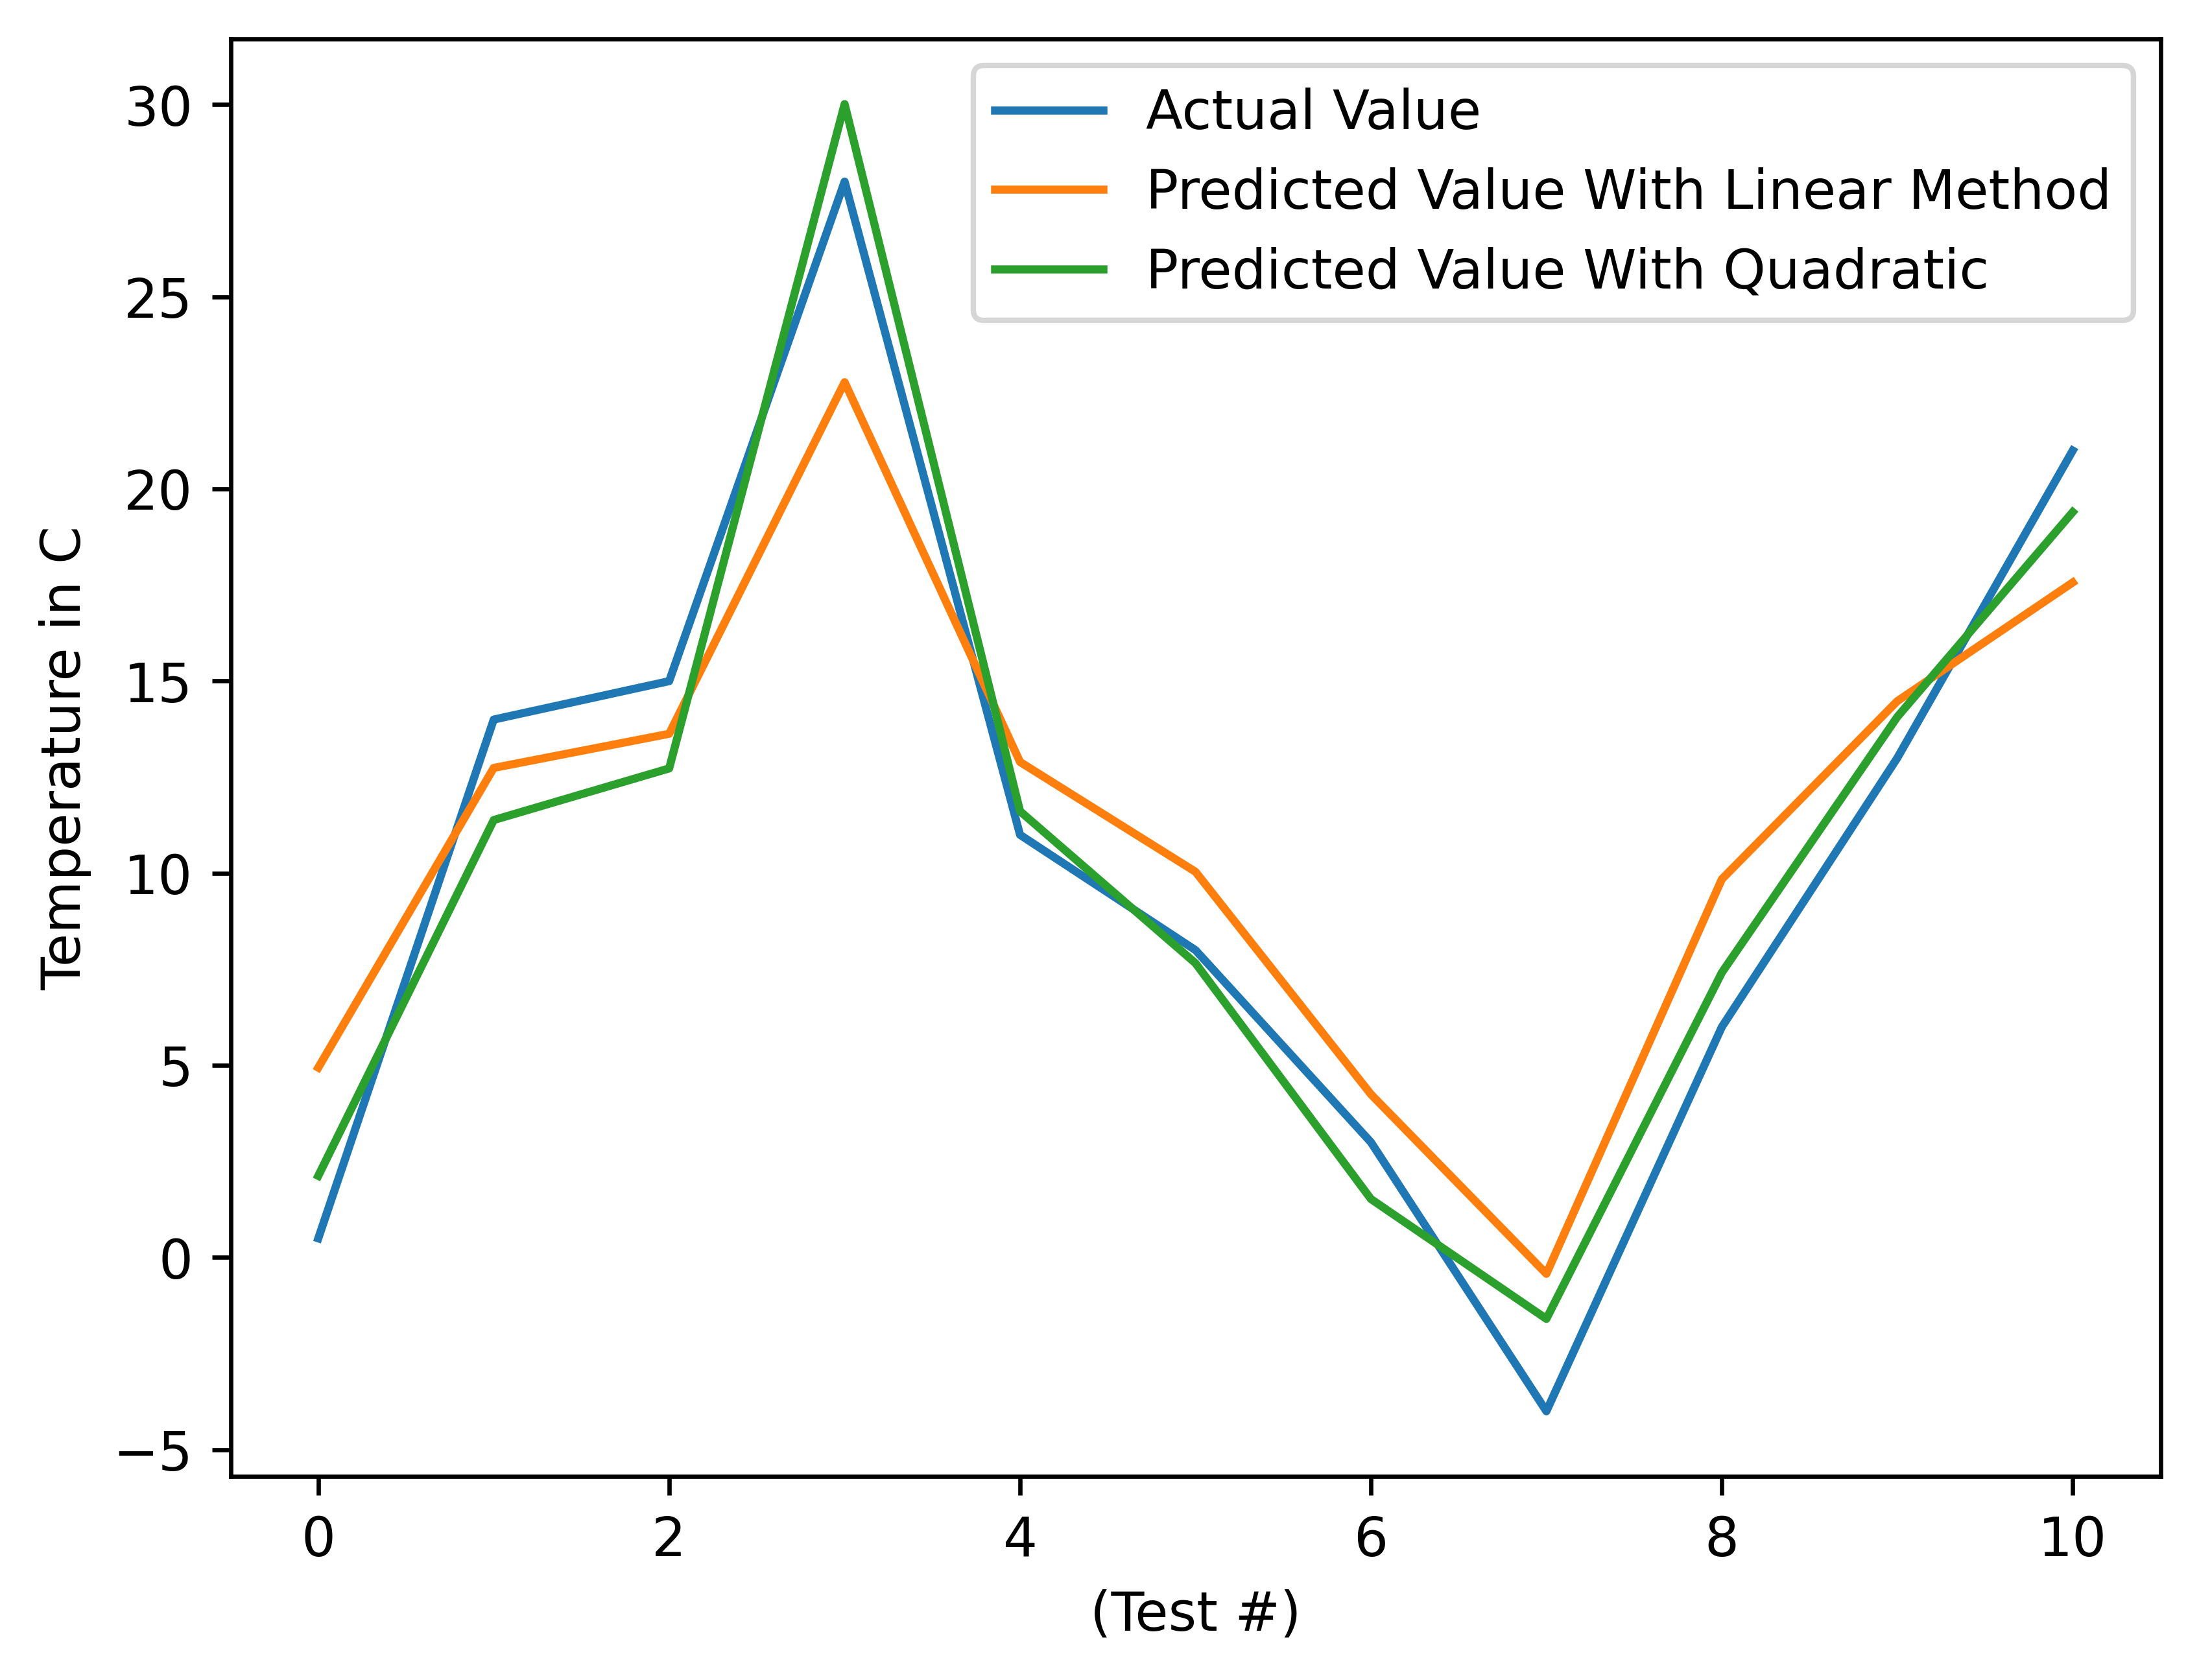

Epoch 500, Loss 50.227482
Epoch 1000, Loss 35.240627
Epoch 1500, Loss 32.020618
Epoch 2000, Loss 31.051996
Epoch 2500, Loss 30.518532
Epoch 3000, Loss 30.073515
Epoch 3500, Loss 29.650671
Epoch 4000, Loss 29.237286
Epoch 4500, Loss 28.830839
Epoch 5000, Loss 28.430779
Epoch 500, Loss 10.399326
Epoch 1000, Loss 9.631797
Epoch 1500, Loss 8.945373
Epoch 2000, Loss 8.331448
Epoch 2500, Loss 7.782350
Epoch 3000, Loss 7.291213
Epoch 3500, Loss 6.851890
Epoch 4000, Loss 6.458900
Epoch 4500, Loss 6.107330
Epoch 5000, Loss 5.792794


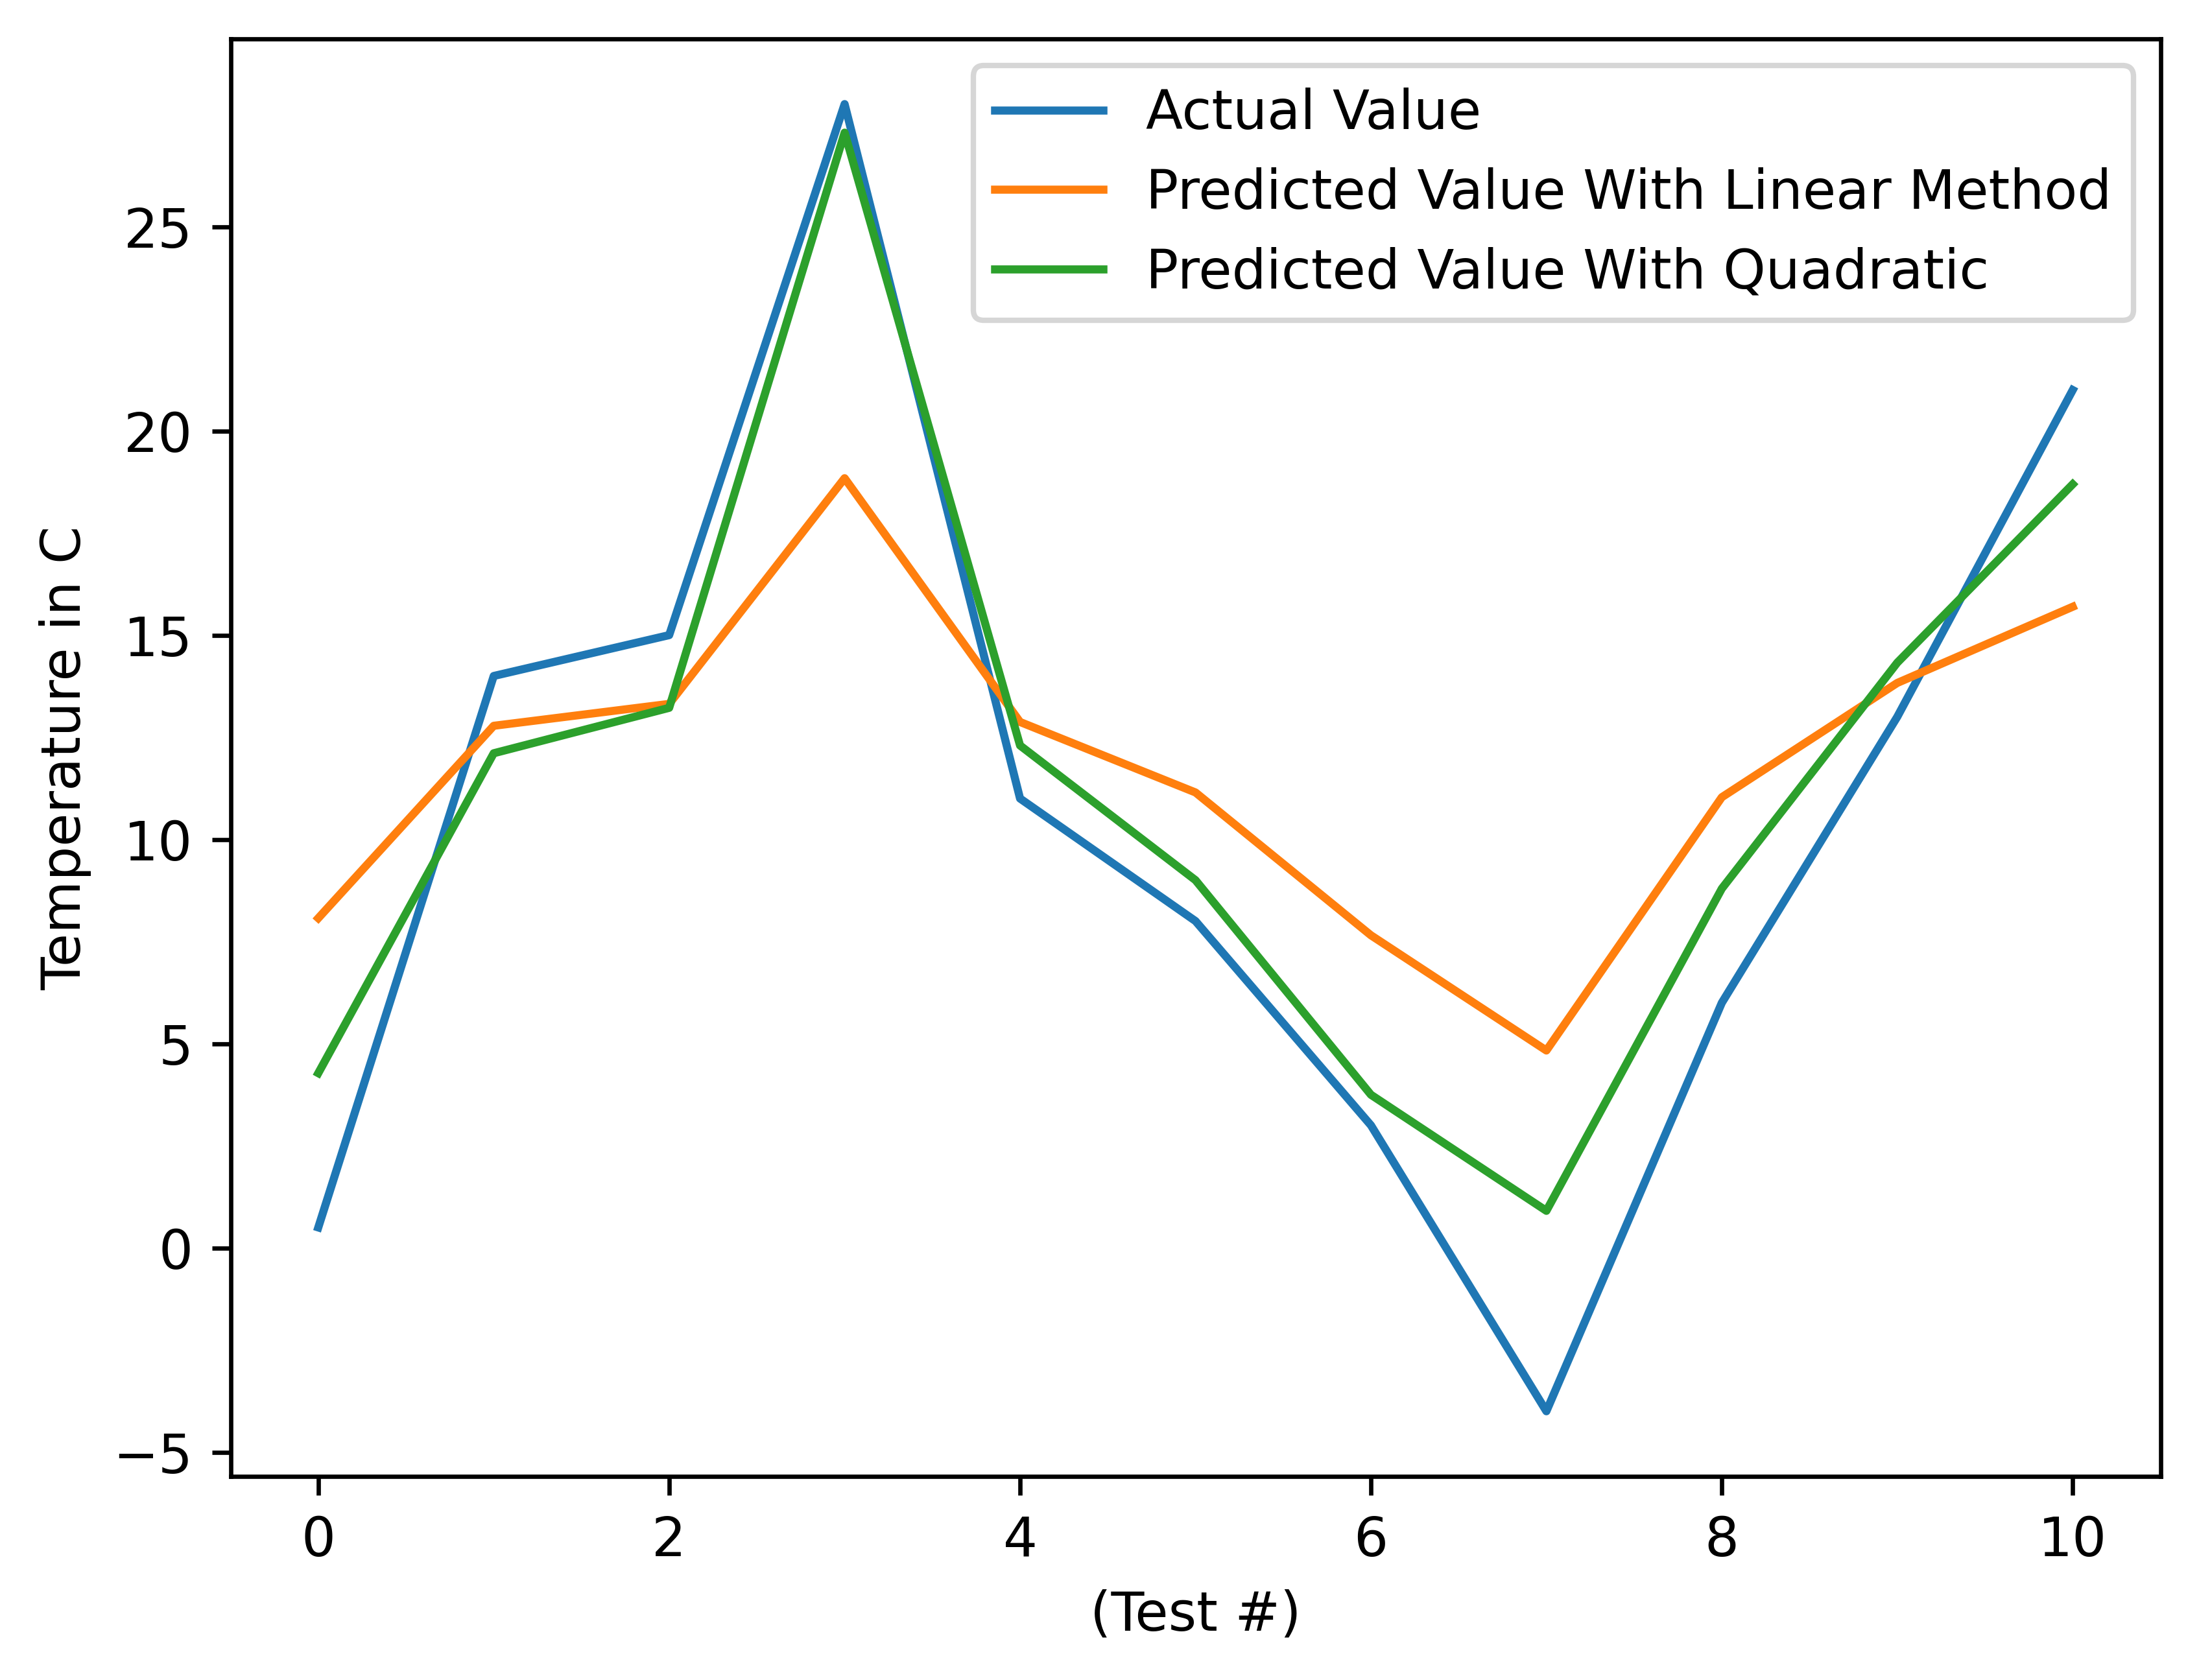

In [ ]:
import torch as pt
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

#filepath = "/content/Cancer.csv"

#df = pd.read_csv(filepath)

#t_u = df.values[:, 2:-1]
#t_c = df.values[:, -1]

t_c = [0.5, 14.0, 15.0, 28.0, 11.0, 8.0, 3.0, -4.0, 6.0, 13.0, 21.0]
t_u = [35.7, 55.9, 58.2, 81.9, 56.3, 48.9, 33.9, 21.8, 48.4, 60.4, 68.4]
t_c = pt.tensor(t_c)
t_u = pt.tensor(t_u)

t_u = 0.05 * t_u

def model(t_u, params, method="linear"):
  if method == "linear":
    return params[0] * t_u + params[1]
  elif method == "quadratic":
    return params[0] * t_u ** 2 + params[1] * t_u + params[2]

def loss_fn(t_p, t_c):
  squared_diffs = (t_p-t_c)**2
  return squared_diffs.mean()

def training_loop(n_epochs, optimizer, params, t_u, t_c, method="linear"):
  for epoch in range(1, n_epochs + 1):
    t_p = model(t_u, params, method=method)
    loss = loss_fn(t_p, t_c)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 500 == 0:
      print('Epoch %d, Loss %f' % (epoch, float(loss)))
  return params
def train_with_method(method, t_u, t_c, lr=0.01):
  if method == "linear":
    params = pt.tensor([1.0, 0.0], requires_grad=True)
  elif method == "quadratic":
    params = pt.tensor([1.0, 1.0, 0.0], requires_grad=True)
  optimizer = pt.optim.SGD([params], lr=lr)
  results = training_loop(
      n_epochs = 5000,
      optimizer = optimizer,
      params = params,
      method = method,
      t_u = t_u,
      t_c = t_c
  )
  return model(t_u, results, method=method)
def training_loop_pt(t_u, t_c, lr=0.01):
  t_p_linear = train_with_method("linear", t_u, t_c, lr)
  t_p_quadratic = train_with_method("quadratic", t_u, t_c, lr)
  fig = plt.figure(dpi=600)
  plt.xlabel("(Test #)")
  plt.ylabel("Temperature in C")
  plt.plot(np.arange(len(t_u)), t_c.detach().numpy(), label="Actual Value")
  plt.plot(np.arange(len(t_u)), t_p_linear.detach().numpy(), label="Predicted Value With Linear Method")
  plt.plot(np.arange(len(t_u)), t_p_quadratic.detach().numpy(), label="Predicted Value With Quadratic")
  plt.legend()
  plt.show()
training_loop_pt(t_u, t_c, lr=0.1)
training_loop_pt(t_u, t_c)
training_loop_pt(t_u, t_c, lr=0.001)
training_loop_pt(t_u, t_c, lr=0.0001)


/tmp/ipykernel_2601/1038153394.py:67: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  print('Epoch %d, Loss %f' % (epoch, float(loss)))
/tmp/ipykernel_2601/1038153394.py:97: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  params[-1] = scaler_y.scale_ * params[-1] - scaler_y.scale_ * sum_term + scaler_y.mean_


Epoch 50, Loss 0.425550
Epoch 100, Loss 0.425550
Epoch 150, Loss 0.425550
Epoch 200, Loss 0.425550
Epoch 250, Loss 0.425550
Epoch 300, Loss 0.425550
Epoch 350, Loss 0.425550
Epoch 400, Loss 0.425550
Epoch 450, Loss 0.425550
Epoch 500, Loss 0.425550


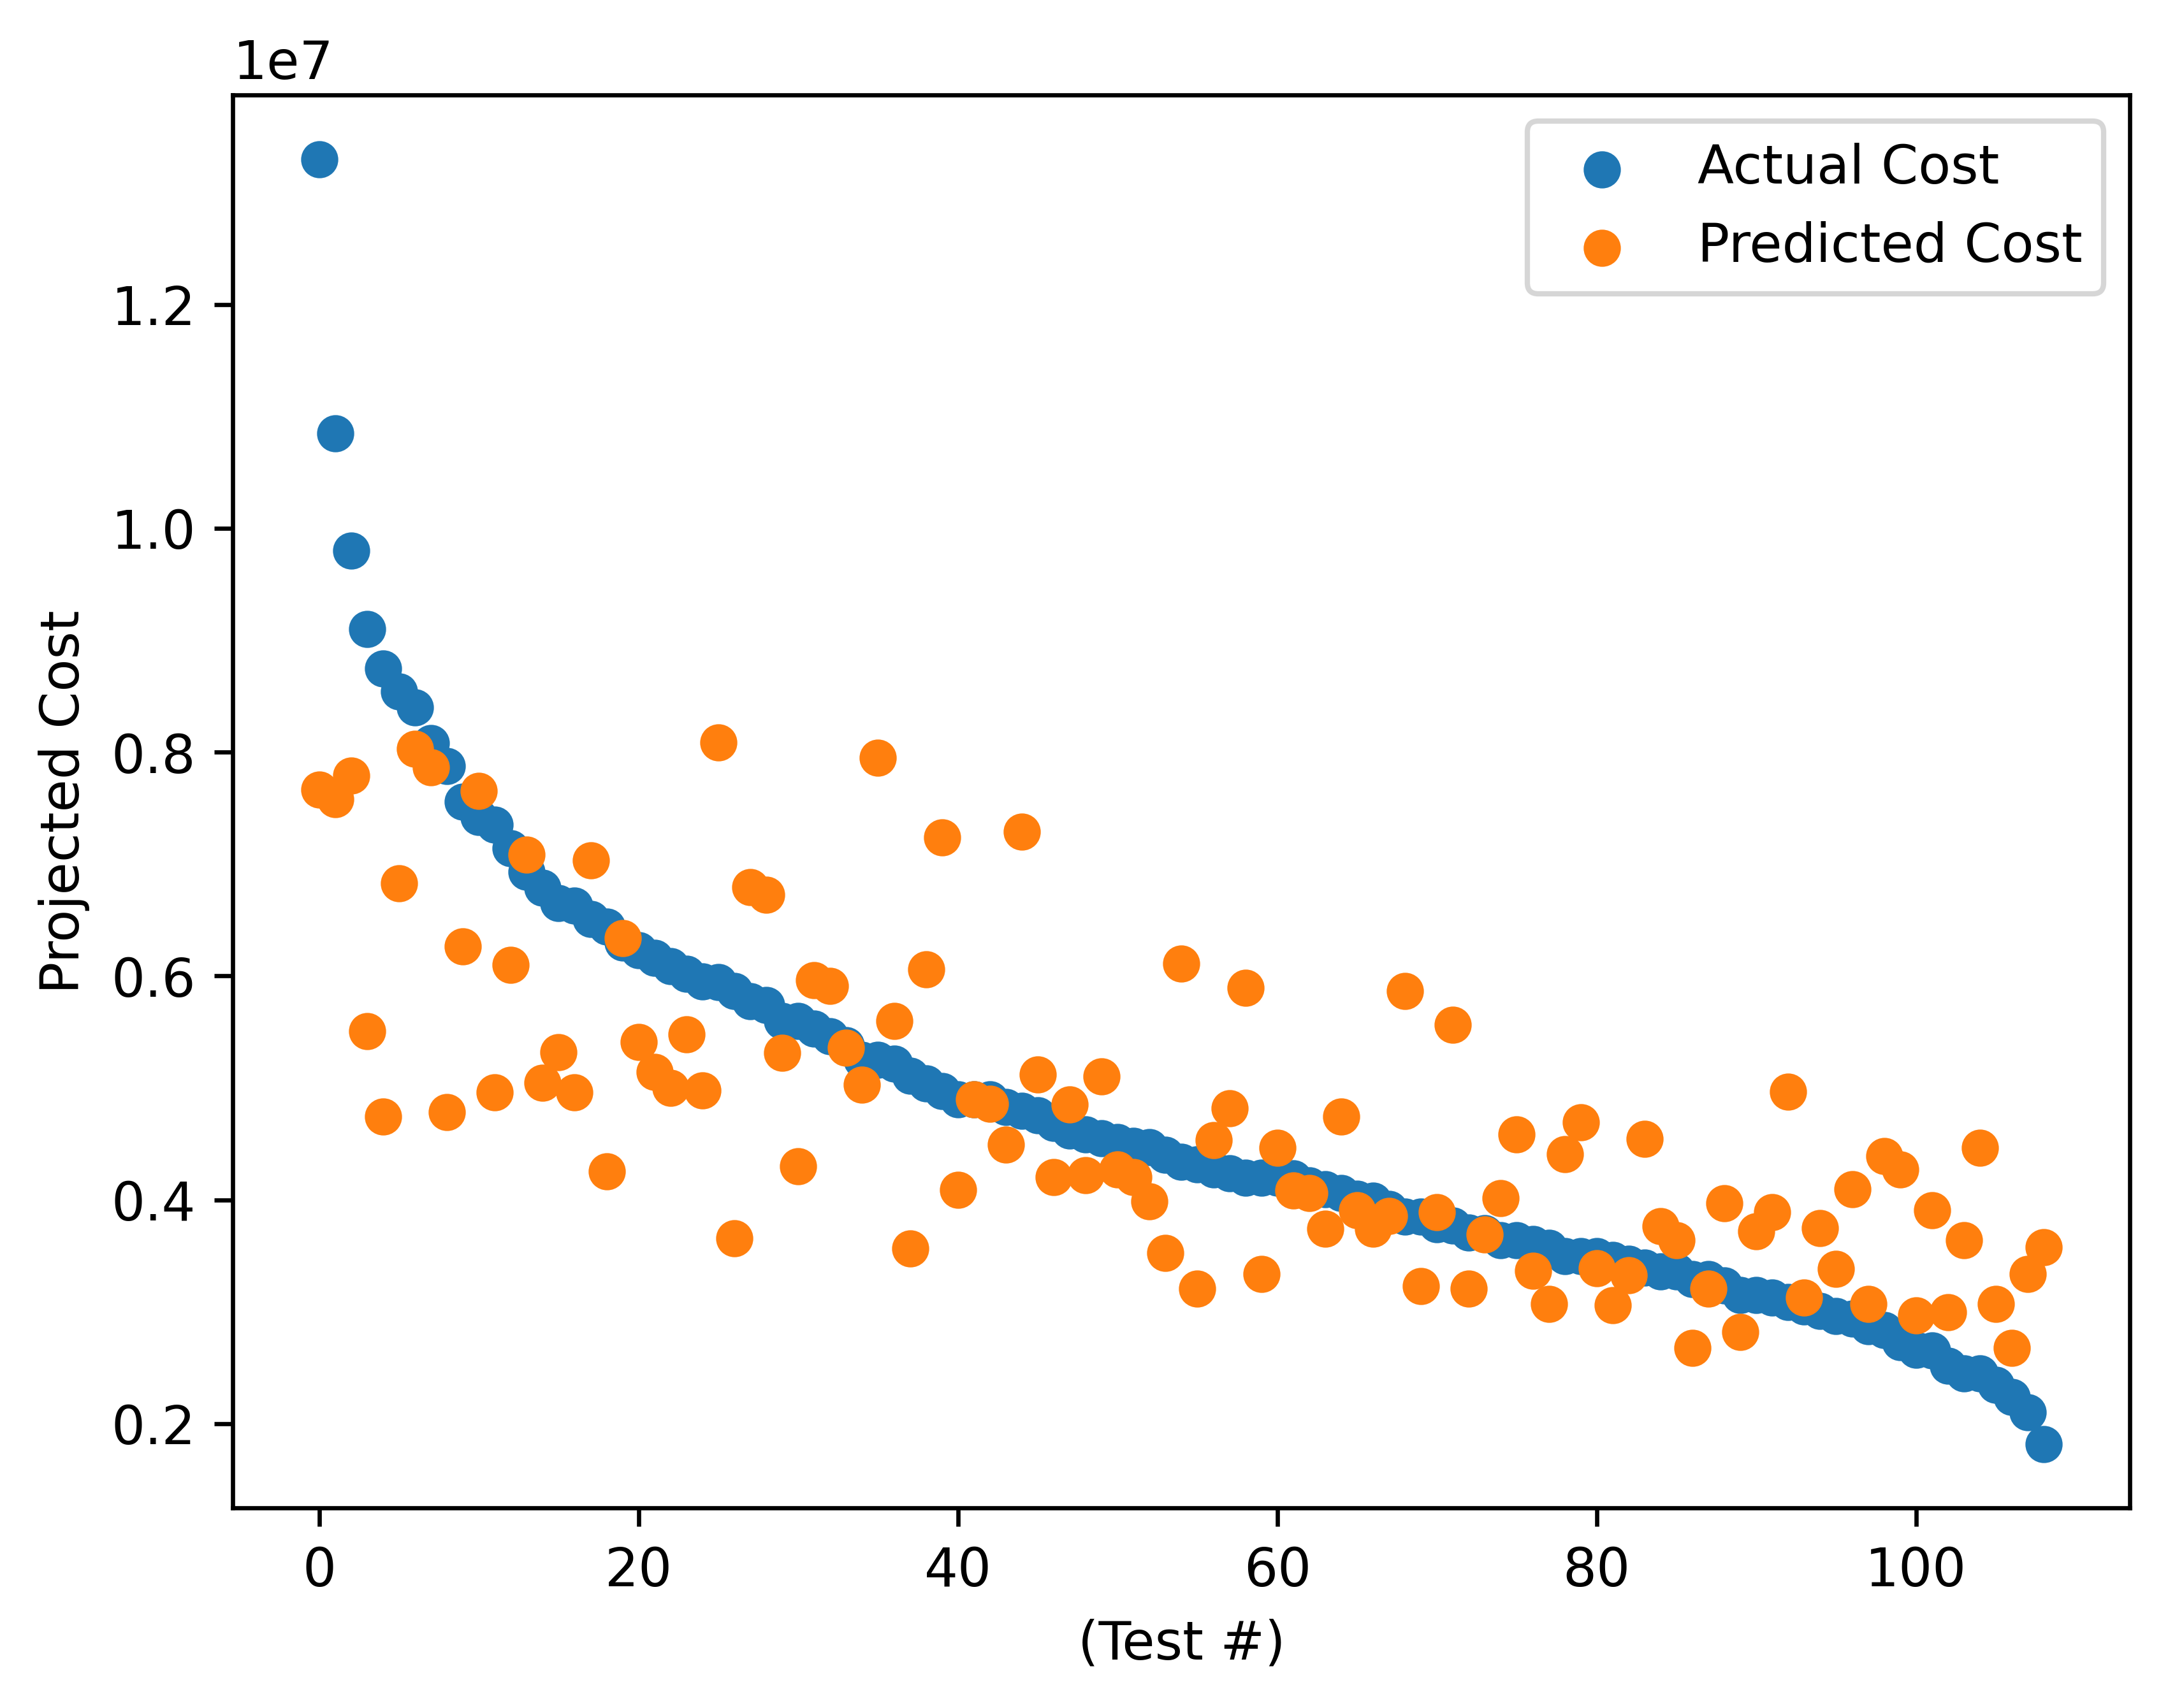

Validation Loss:  915692850000.0
Parameters: 
329.510559x1 + 178699.234375x2 + 1133020.375000x3 + 540399.687500x4 + 372143.187500x5 + -167288.890625
Epoch 50, Loss 0.449305
Epoch 100, Loss 0.429009
Epoch 150, Loss 0.426458
Epoch 200, Loss 0.425814
Epoch 250, Loss 0.425629
Epoch 300, Loss 0.425574
Epoch 350, Loss 0.425557
Epoch 400, Loss 0.425552
Epoch 450, Loss 0.425551
Epoch 500, Loss 0.425550


/tmp/ipykernel_2601/1038153394.py:97: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  params[-1] = scaler_y.scale_ * params[-1] - scaler_y.scale_ * sum_term + scaler_y.mean_


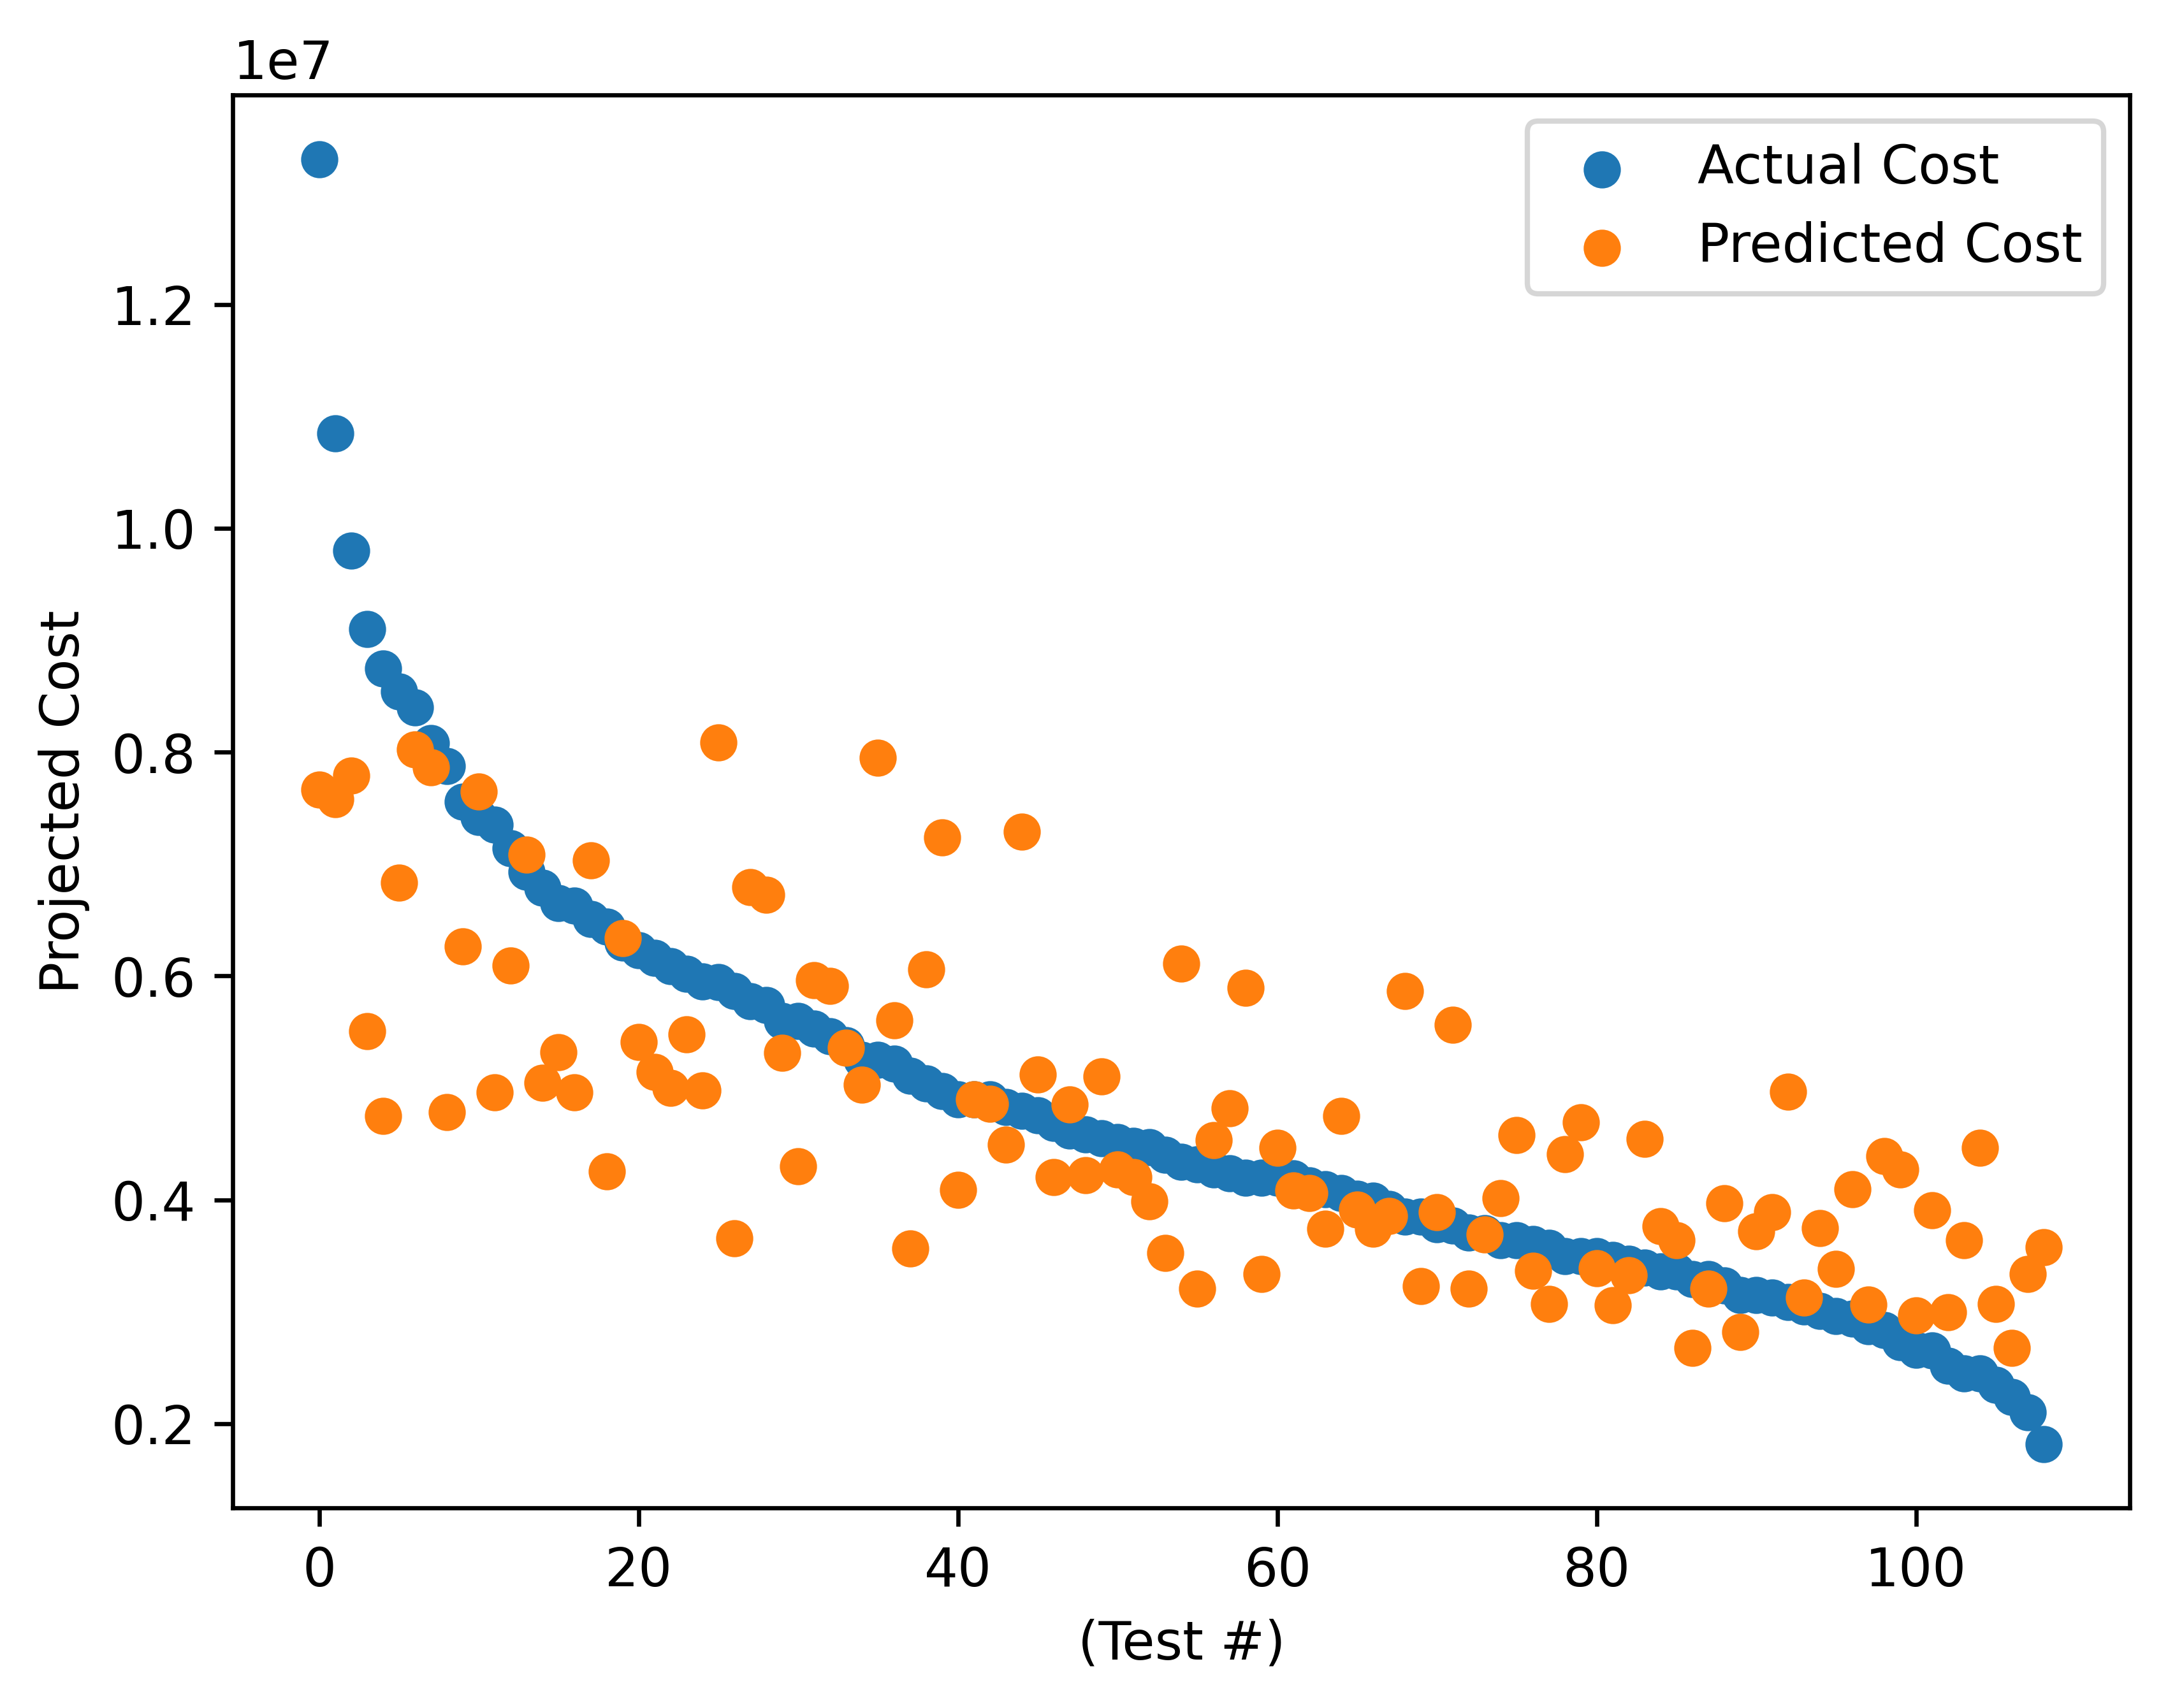

Validation Loss:  915716240000.0
Parameters: 
329.373627x1 + 179808.796875x2 + 1132535.750000x3 + 539733.437500x4 + 372398.968750x5 + -168243.640625
Epoch 50, Loss 0.828359
Epoch 100, Loss 0.707628
Epoch 150, Loss 0.624494
Epoch 200, Loss 0.567045
Epoch 250, Loss 0.527174
Epoch 300, Loss 0.499359
Epoch 350, Loss 0.479833
Epoch 400, Loss 0.466024
Epoch 450, Loss 0.456175
Epoch 500, Loss 0.449079


/tmp/ipykernel_2601/1038153394.py:97: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  params[-1] = scaler_y.scale_ * params[-1] - scaler_y.scale_ * sum_term + scaler_y.mean_


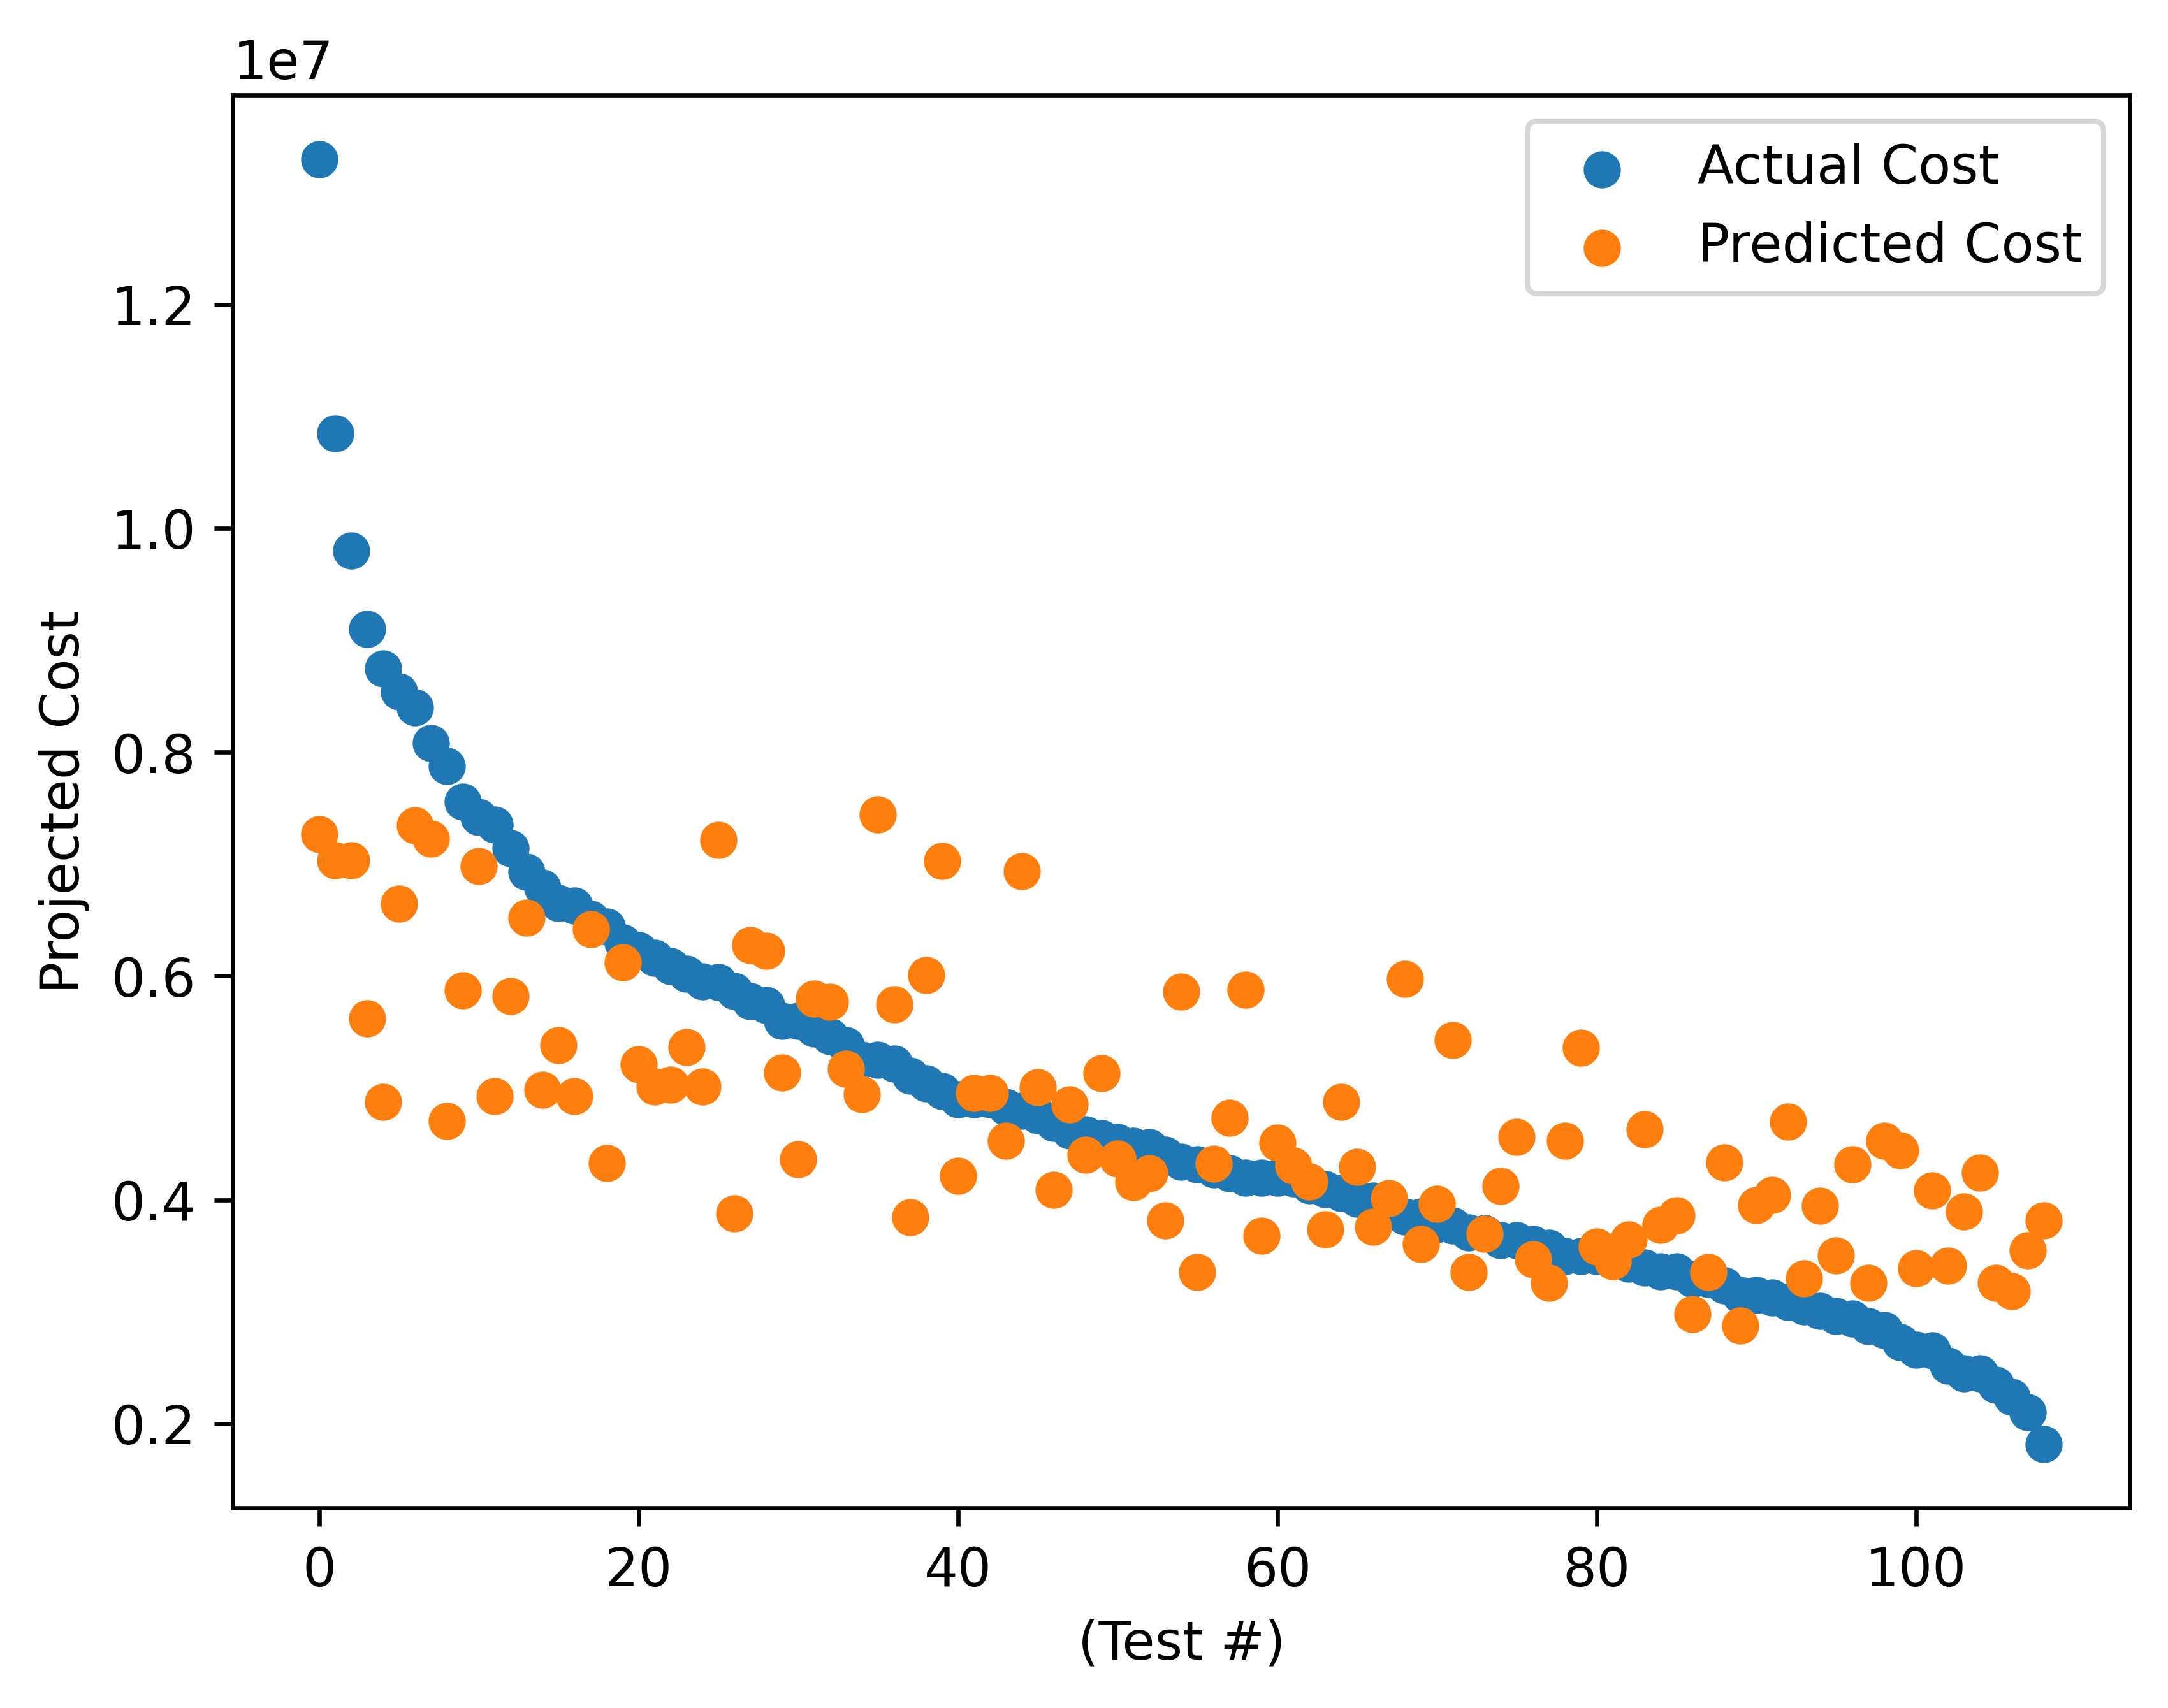

Validation Loss:  960462400000.0
Parameters: 
233.491257x1 + 325753.593750x2 + 891307.750000x3 + 411006.437500x4 + 364385.156250x5 + 439614.500000
Epoch 50, Loss 0.979874
Epoch 100, Loss 0.960091
Epoch 150, Loss 0.941040
Epoch 200, Loss 0.922693
Epoch 250, Loss 0.905026
Epoch 300, Loss 0.888011
Epoch 350, Loss 0.871625
Epoch 400, Loss 0.855843
Epoch 450, Loss 0.840644
Epoch 500, Loss 0.826005


/tmp/ipykernel_2601/1038153394.py:97: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  params[-1] = scaler_y.scale_ * params[-1] - scaler_y.scale_ * sum_term + scaler_y.mean_


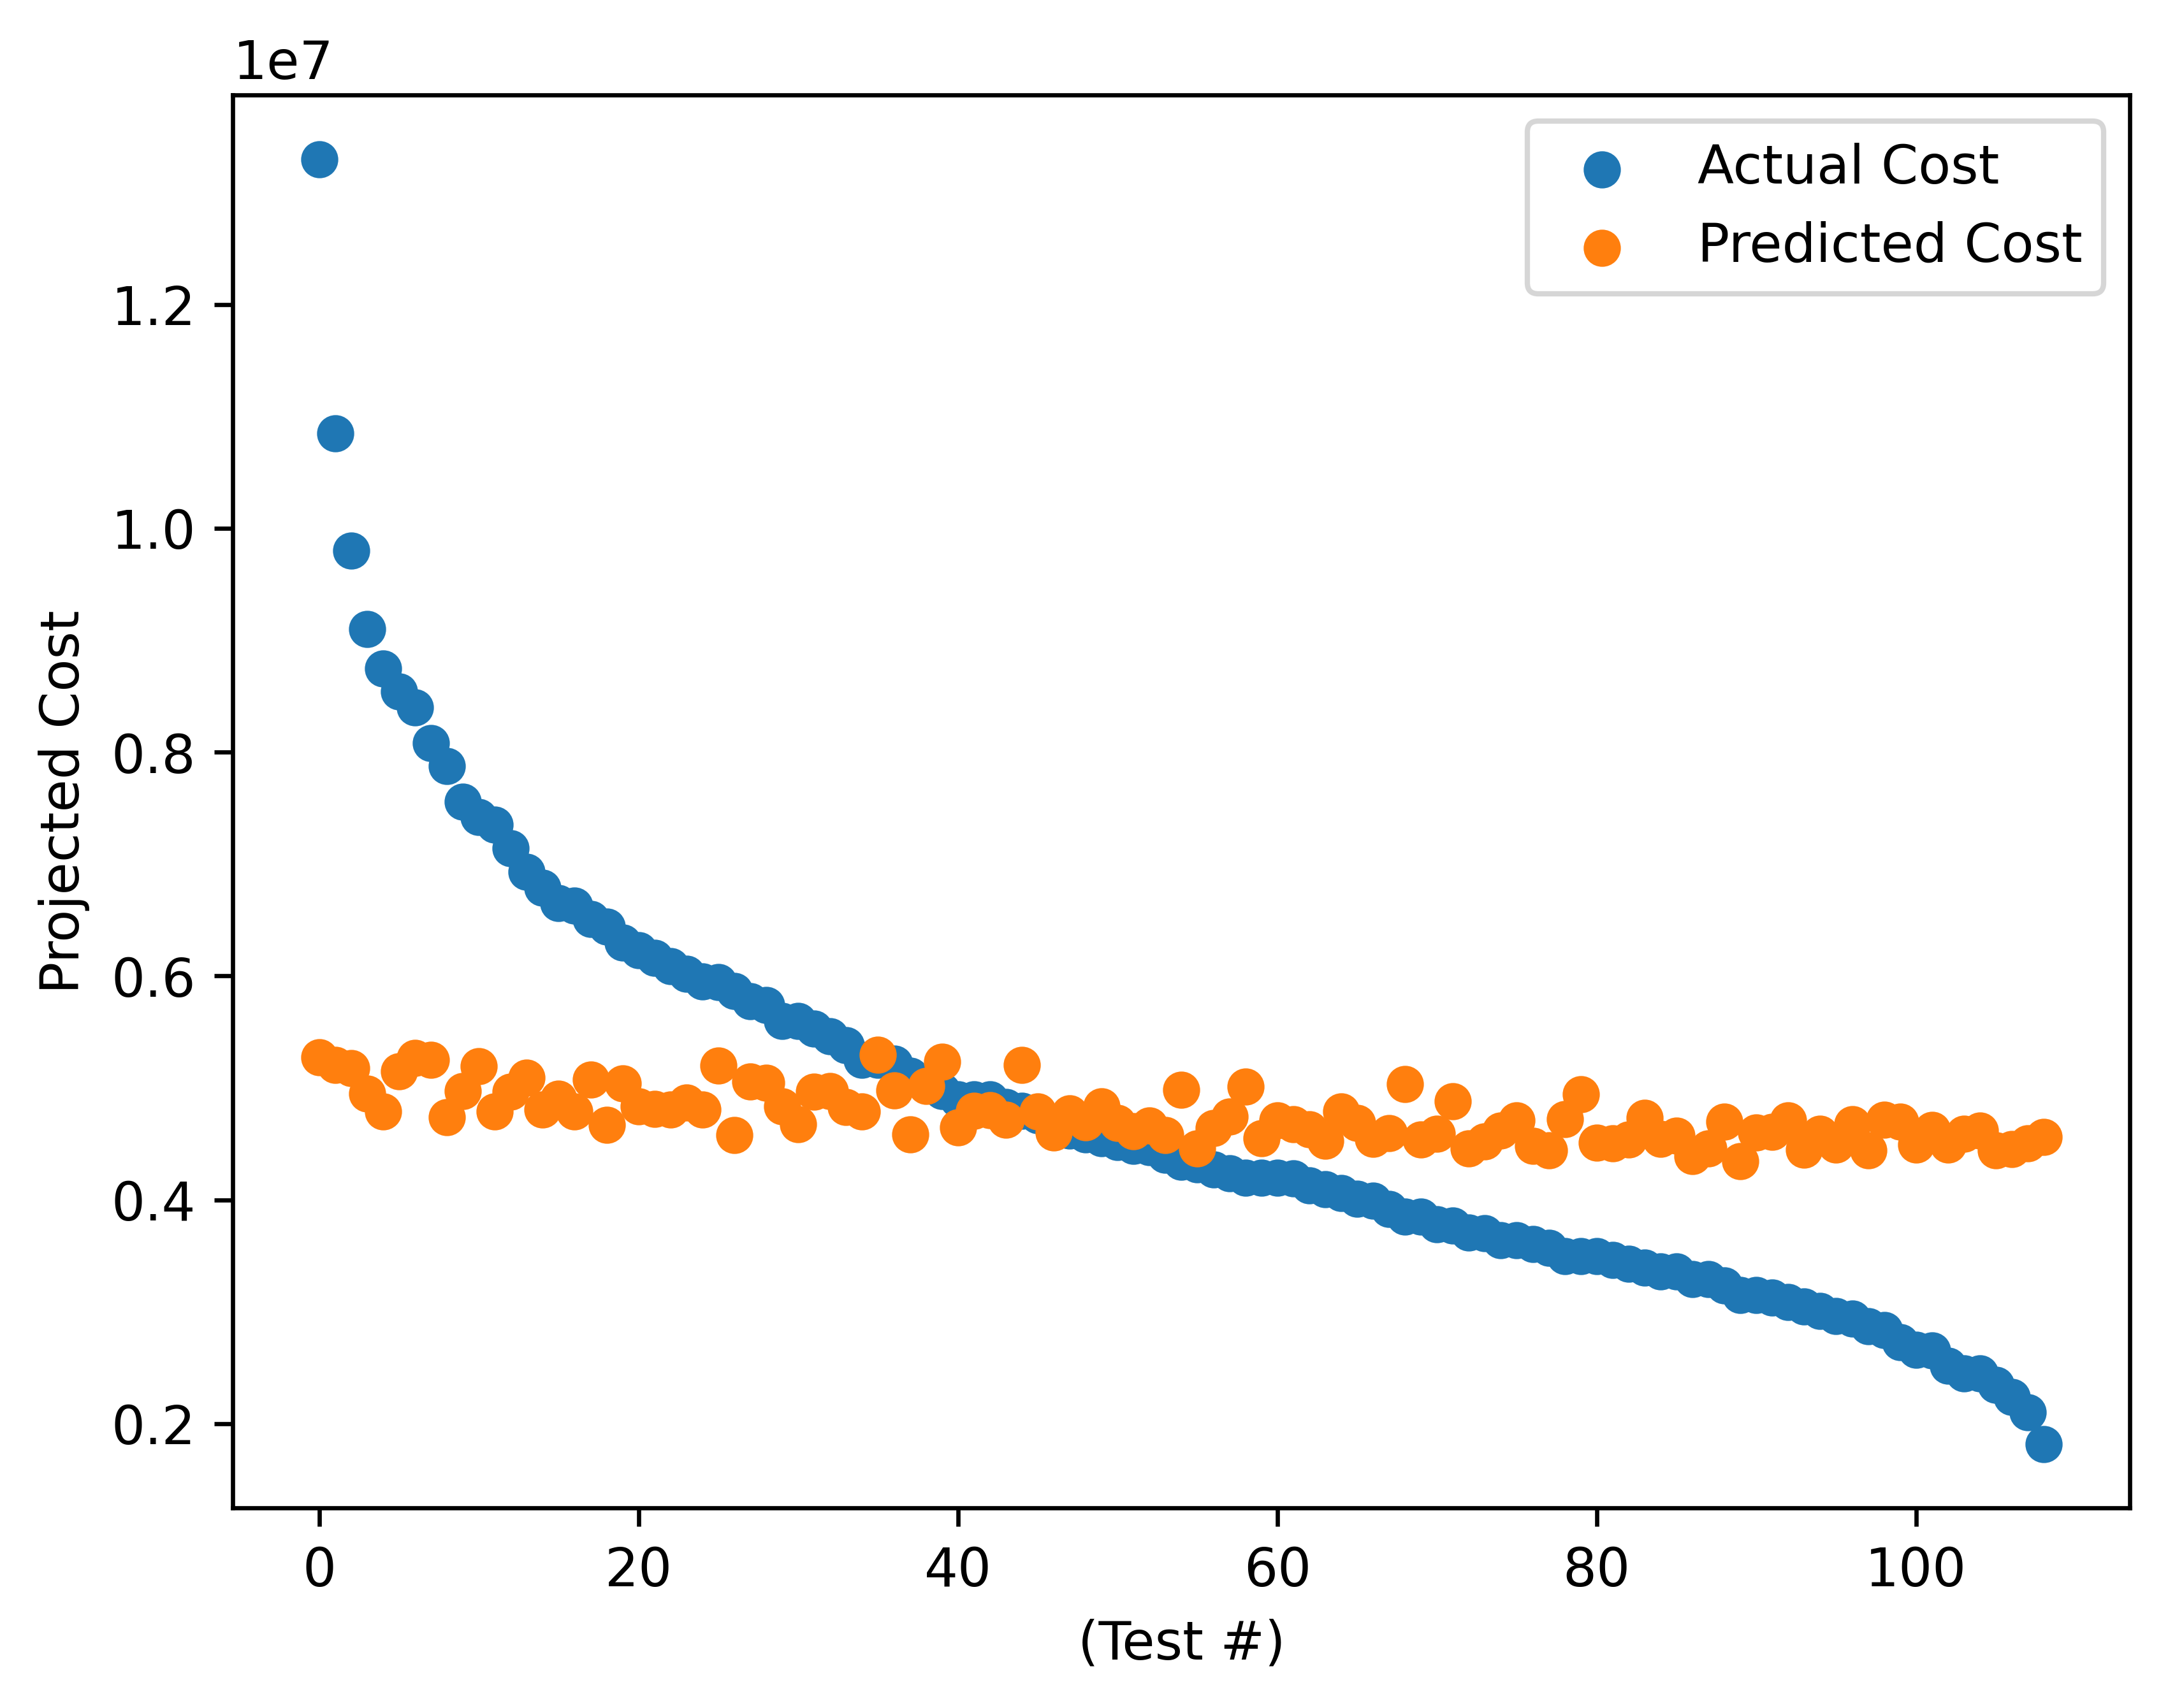

Validation Loss:  1597585800000.0
Parameters: 
42.129501x1 + 83472.000000x2 + 177904.859375x3 + 83541.468750x4 + 75939.257812x5 + 3856731.000000


In [2]:
import torch as pt
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import StandardScaler

filepath = "/content/Housing.csv"

df = pd.read_csv(filepath)

scaler_X = StandardScaler() # Scaler for input features
scaler_XV = StandardScaler() # Scaler for validation input features
scaler_y = StandardScaler() # Scaler for target variable

t_u = df.values[:, [1,2,3,4,10]].astype(np.float32)
t_c = df.values[:, 0].astype(np.float32)


t_o = t_u.copy()
t_o = t_o.T

validation_indices = np.arange(0, len(t_u), 5)




t_uv = t_u[validation_indices]
t_u = np.delete(t_u, validation_indices, axis=0)

t_u = scaler_X.fit_transform(t_u) # Fit and transform input features
t_uv = scaler_XV.fit_transform(t_uv)

t_cv = t_c[validation_indices]
t_c = np.delete(t_c, validation_indices)

t_c = scaler_y.fit_transform(t_c.reshape(-1, 1)).reshape(-1) # Fit and transform target variable

t_c = pt.from_numpy(t_c)
t_u = pt.from_numpy(t_u)
t_uv = pt.from_numpy(t_uv)

def model(t_u, params):
  return t_u @ params[:-1] + params[-1]


def loss_fn(t_p, t_c):
  squared_diffs = (t_p-t_c)**2
  return squared_diffs.mean()

def loss_numpy(res, y):
  for i in range(len(res)):
    res[i] = np.float64(res[i])
  for i in range(len(y)):
    y[i] = np.float64(y[i])
  return np.sum((res - y) ** 2) / (2 * len(res))

def training_loop(n_epochs, optimizer, params, t_u, t_c, method="linear"):
  for epoch in range(1, n_epochs + 1):
    t_p = model(t_u, params)
    loss = loss_fn(t_p, t_c)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 50 == 0:
      print('Epoch %d, Loss %f' % (epoch, float(loss)))
  return params
def train_with_method(t_u, t_c, lr=0.01):
  params = np.zeros(len(t_u[0])+1).astype(np.float32)
  params = pt.tensor(params, requires_grad=True)
  optimizer = pt.optim.SGD([params], lr=lr)
  results = training_loop(
      n_epochs = 500,
      optimizer = optimizer,
      params = params,
      t_u = t_u,
      t_c = t_c
  )
  return results
def train(t_u, t_c, lr=0.01):
  # Training
  params = train_with_method(t_u, t_c, lr)

  # Postprocessing
  t_p = model(t_uv, params)
  t_p = t_p.detach().numpy()
  t_co = scaler_y.inverse_transform(t_c.reshape(-1, 1)).reshape(-1)
  t_p = scaler_y.inverse_transform(t_p.reshape(-1, 1)).reshape(-1)
  cf = loss_numpy(t_p, t_cv)
  t_c = t_co

  params = params.detach().numpy()

  params[:-1] = (scaler_y.scale_ * params[:-1]) / scaler_X.scale_
  sum_term = np.sum((params[:-1] * scaler_X.mean_) / scaler_y.scale_)
  params[-1] = scaler_y.scale_ * params[-1] - scaler_y.scale_ * sum_term + scaler_y.mean_

  # Display
  fig = plt.figure(dpi=600)
  plt.xlabel("(Test #)")
  plt.ylabel("Projected Cost")
  plt.scatter(np.arange(len(t_uv)), t_cv, label="Actual Cost")
  plt.scatter(np.arange(len(t_uv)), t_p, label="Predicted Cost")
  plt.legend()
  plt.show()
  print("Validation Loss: ", cf)
  print(f"Parameters: ")
  for i in range (len(params) - 1):
    print(f"{params[i]:.6f}x{i+1} +", end = " ")
  print(f"{params[len(params) - 1]:.6f}")
train(t_u, t_c, lr=0.1)
train(t_u, t_c)
train(t_u, t_c, lr=0.001)
train(t_u, t_c, lr=0.0001)

Epoch 50, Loss 0.313278
Epoch 100, Loss 0.313277
Epoch 150, Loss 0.313277
Epoch 200, Loss 0.313277
Epoch 250, Loss 0.313277
Epoch 300, Loss 0.313277
Epoch 350, Loss 0.313277
Epoch 400, Loss 0.313277
Epoch 450, Loss 0.313277
Epoch 500, Loss 0.313277


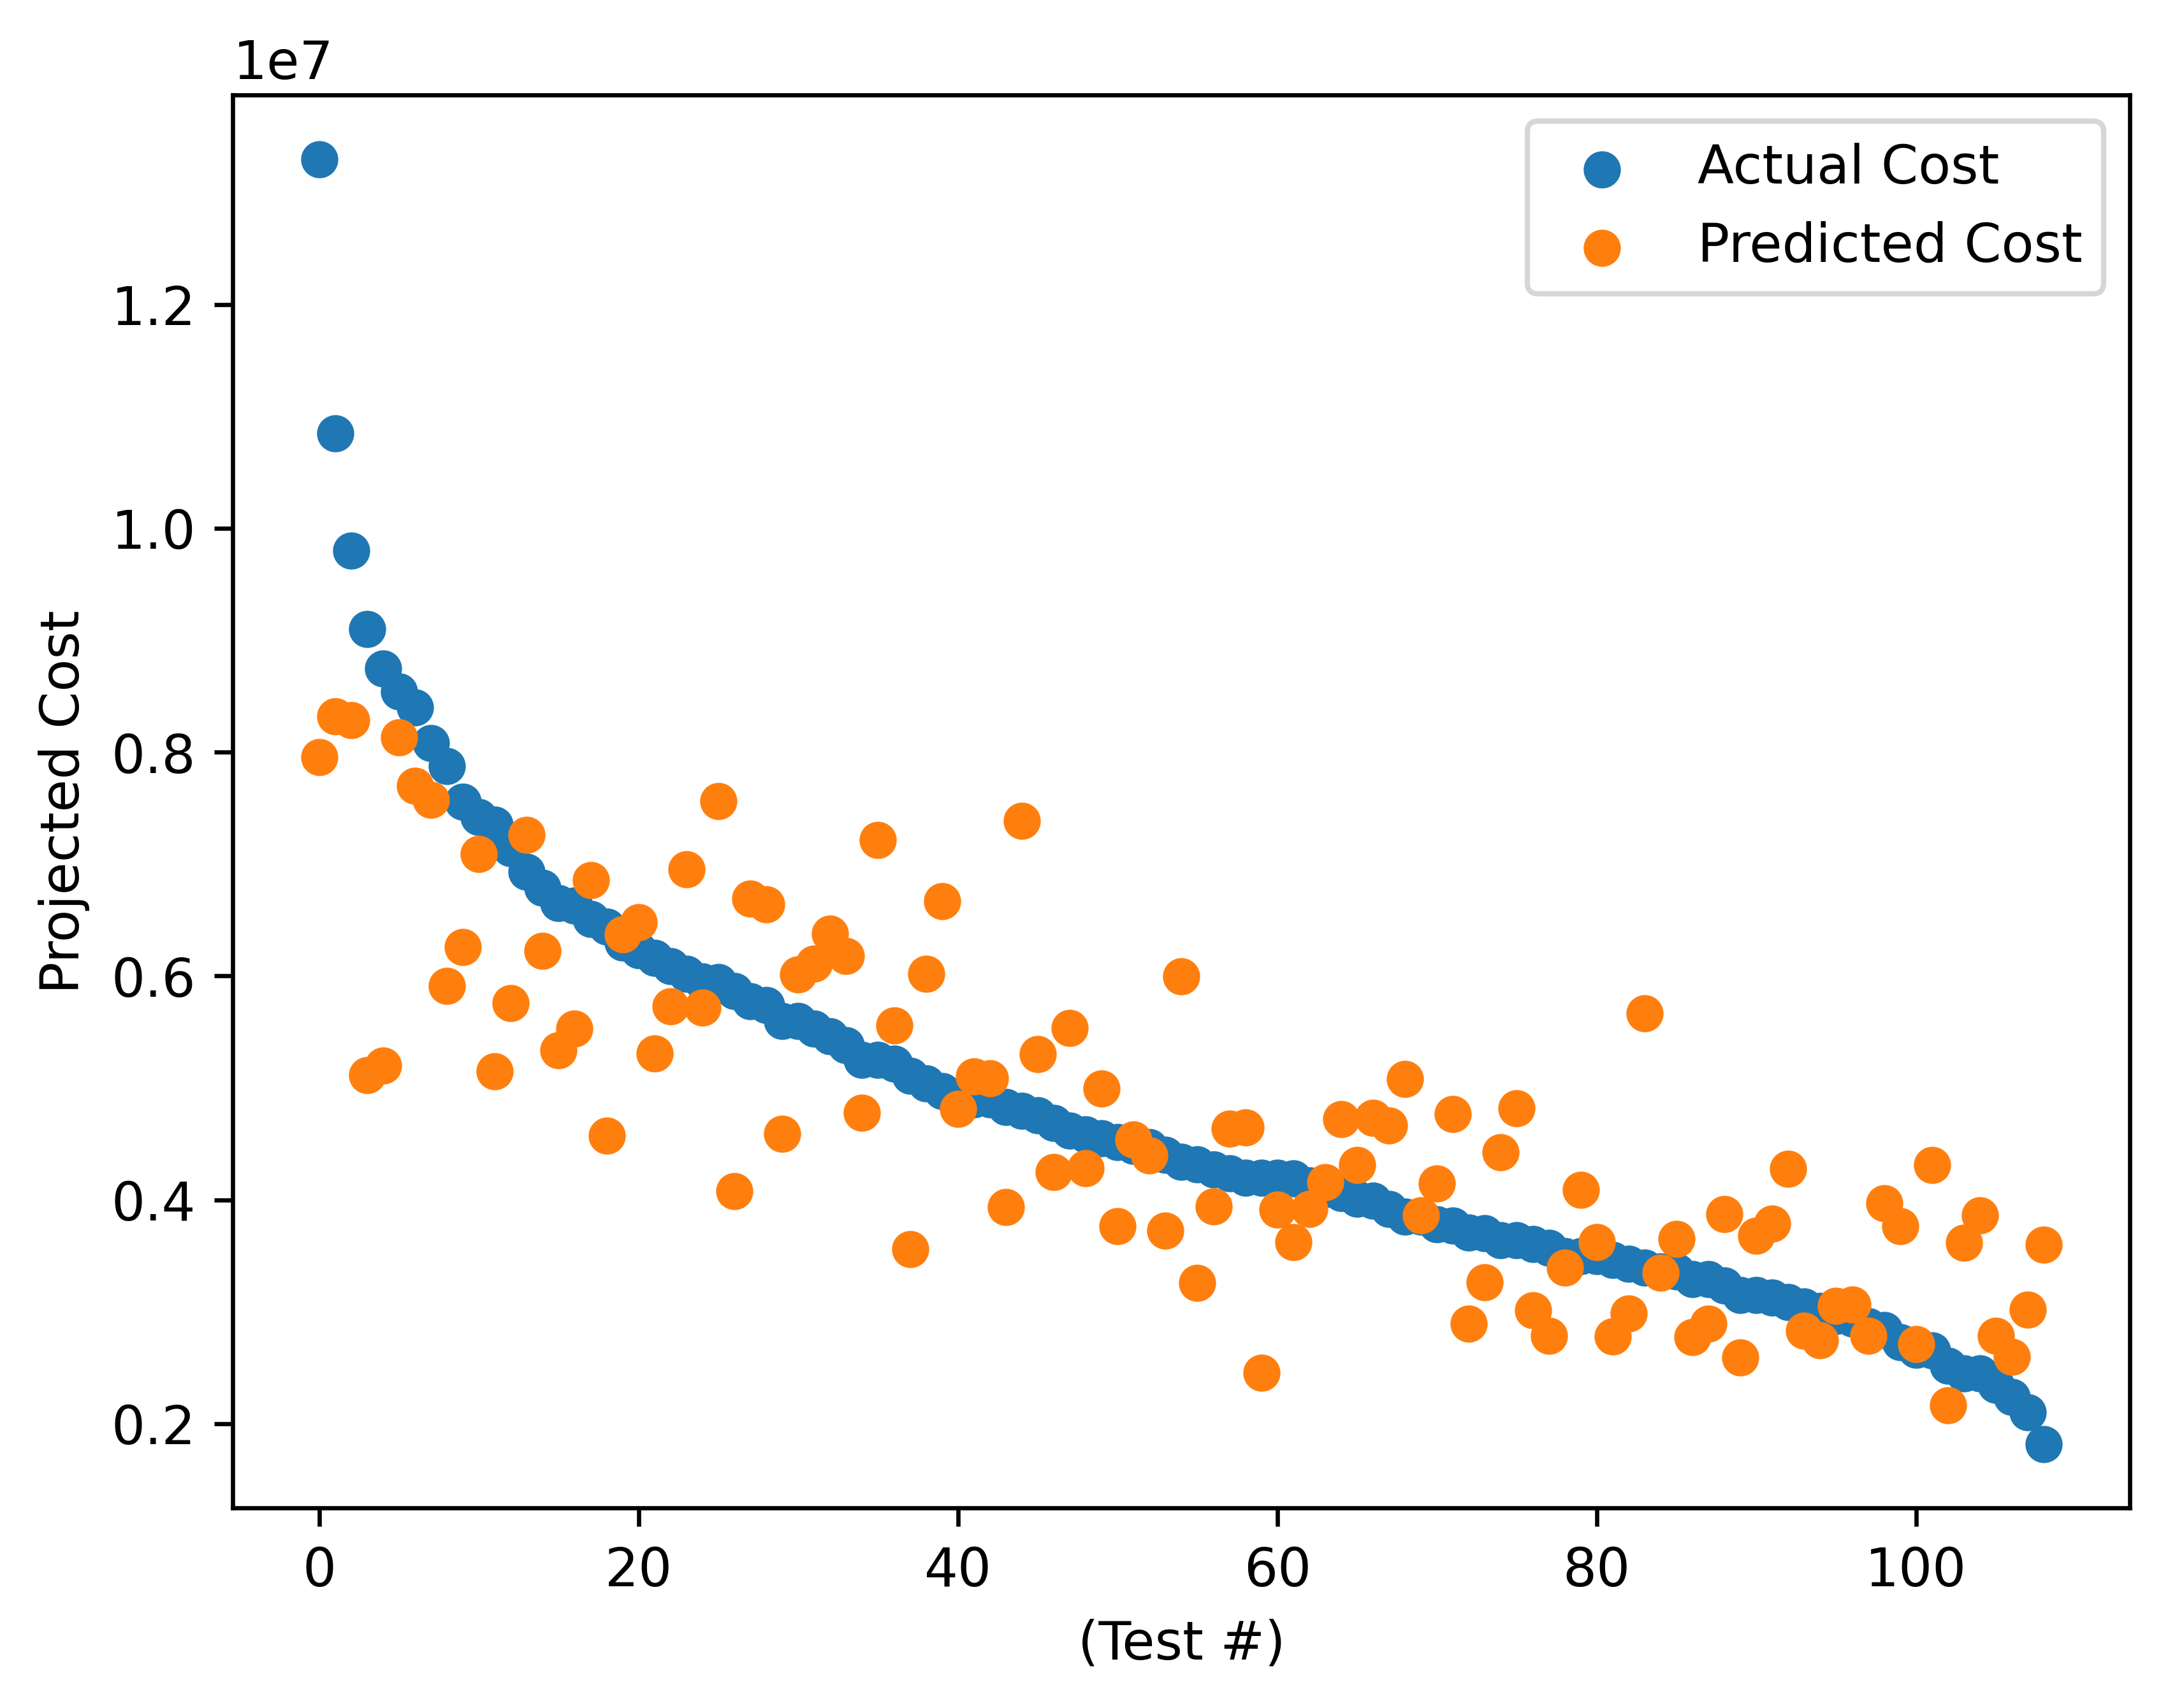

Validation Loss:  723113300000.0
Parameters: 
254.003113x1 + 138342.312500x2 + 984734.625000x3 + 441276.687500x4 + 450206.937500x5 + 432303.000000x6 + 359581.812500x7 + 908651.562500x8 + 878796.500000x9 + 315082.781250x10 + 524480.375000x11 + -270842.593750
Epoch 50, Loss 0.327204
Epoch 100, Loss 0.315776
Epoch 150, Loss 0.314082
Epoch 200, Loss 0.313560
Epoch 250, Loss 0.313383
Epoch 300, Loss 0.313318
Epoch 350, Loss 0.313294
Epoch 400, Loss 0.313284
Epoch 450, Loss 0.313280
Epoch 500, Loss 0.313278


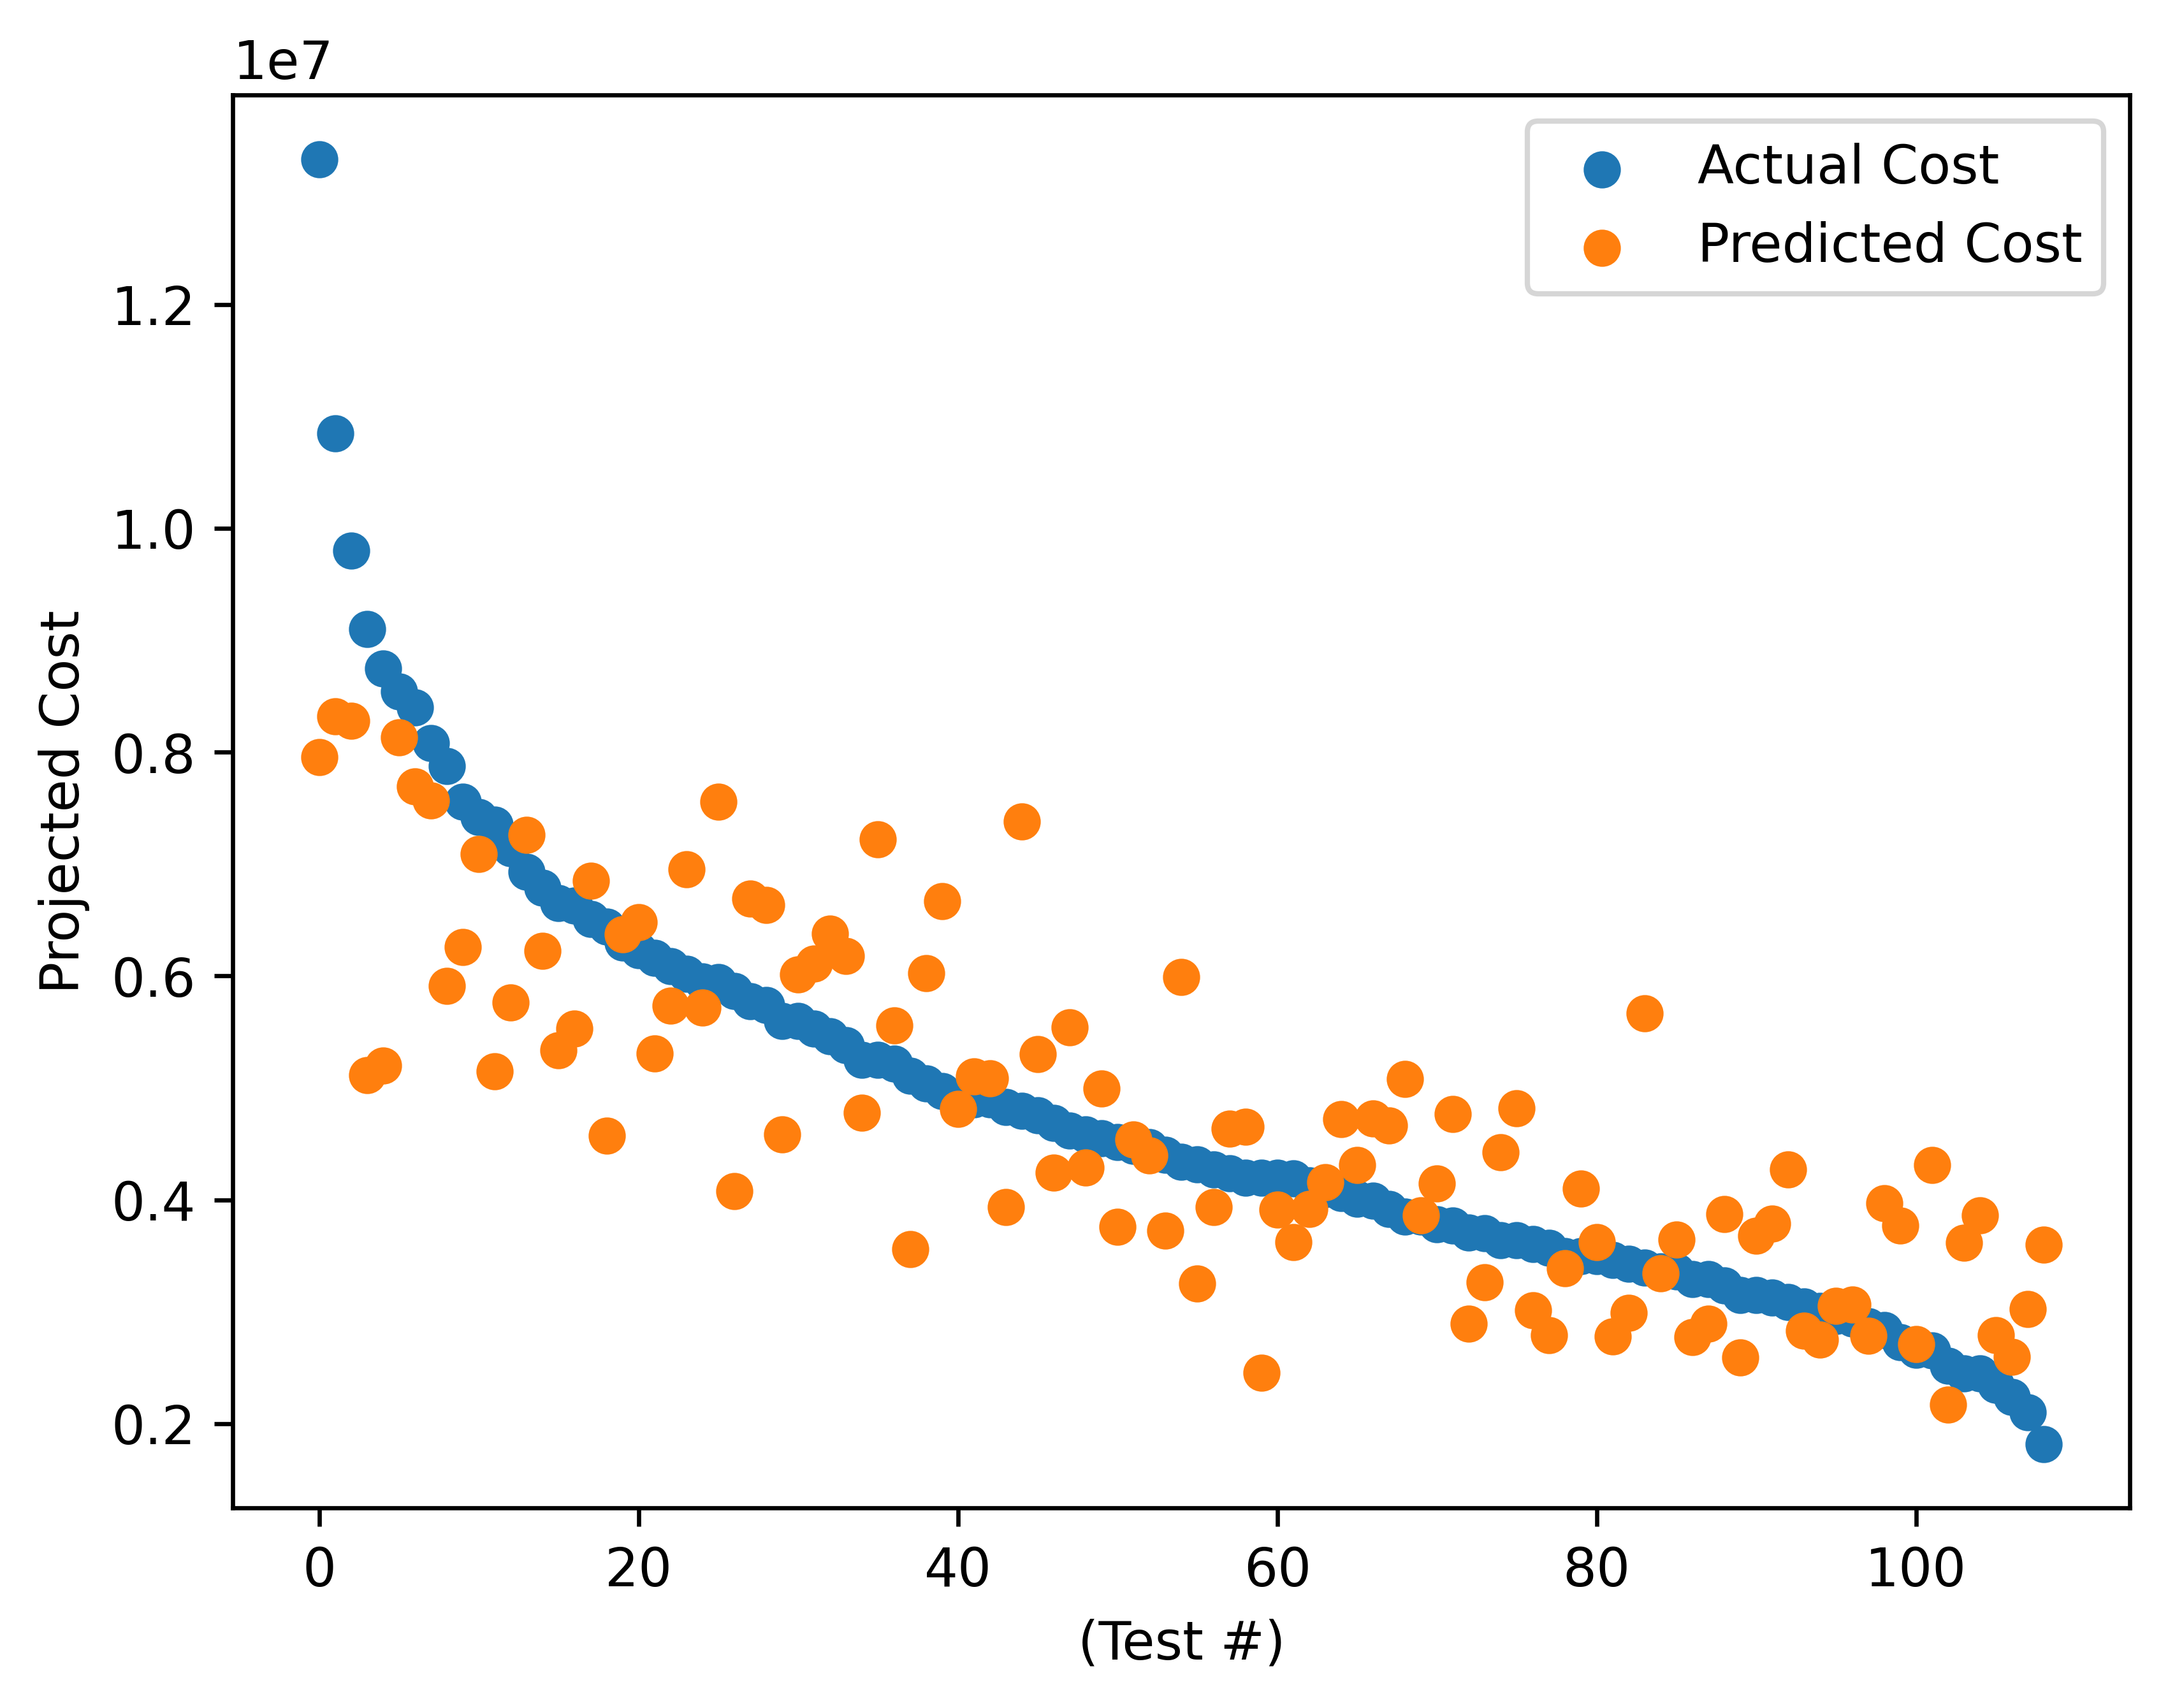

Validation Loss:  723259000000.0
Parameters: 
253.584366x1 + 140404.468750x2 + 984780.812500x3 + 439187.500000x4 + 451699.093750x5 + 434578.156250x6 + 356579.937500x7 + 908907.437500x8 + 879620.937500x9 + 315208.750000x10 + 525248.250000x11 + -272292.562500
Epoch 50, Loss 0.752383
Epoch 100, Loss 0.593306
Epoch 150, Loss 0.493430
Epoch 200, Loss 0.430528
Epoch 250, Loss 0.390742
Epoch 300, Loss 0.365431
Epoch 350, Loss 0.349203
Epoch 400, Loss 0.338690
Epoch 450, Loss 0.331787
Epoch 500, Loss 0.327177


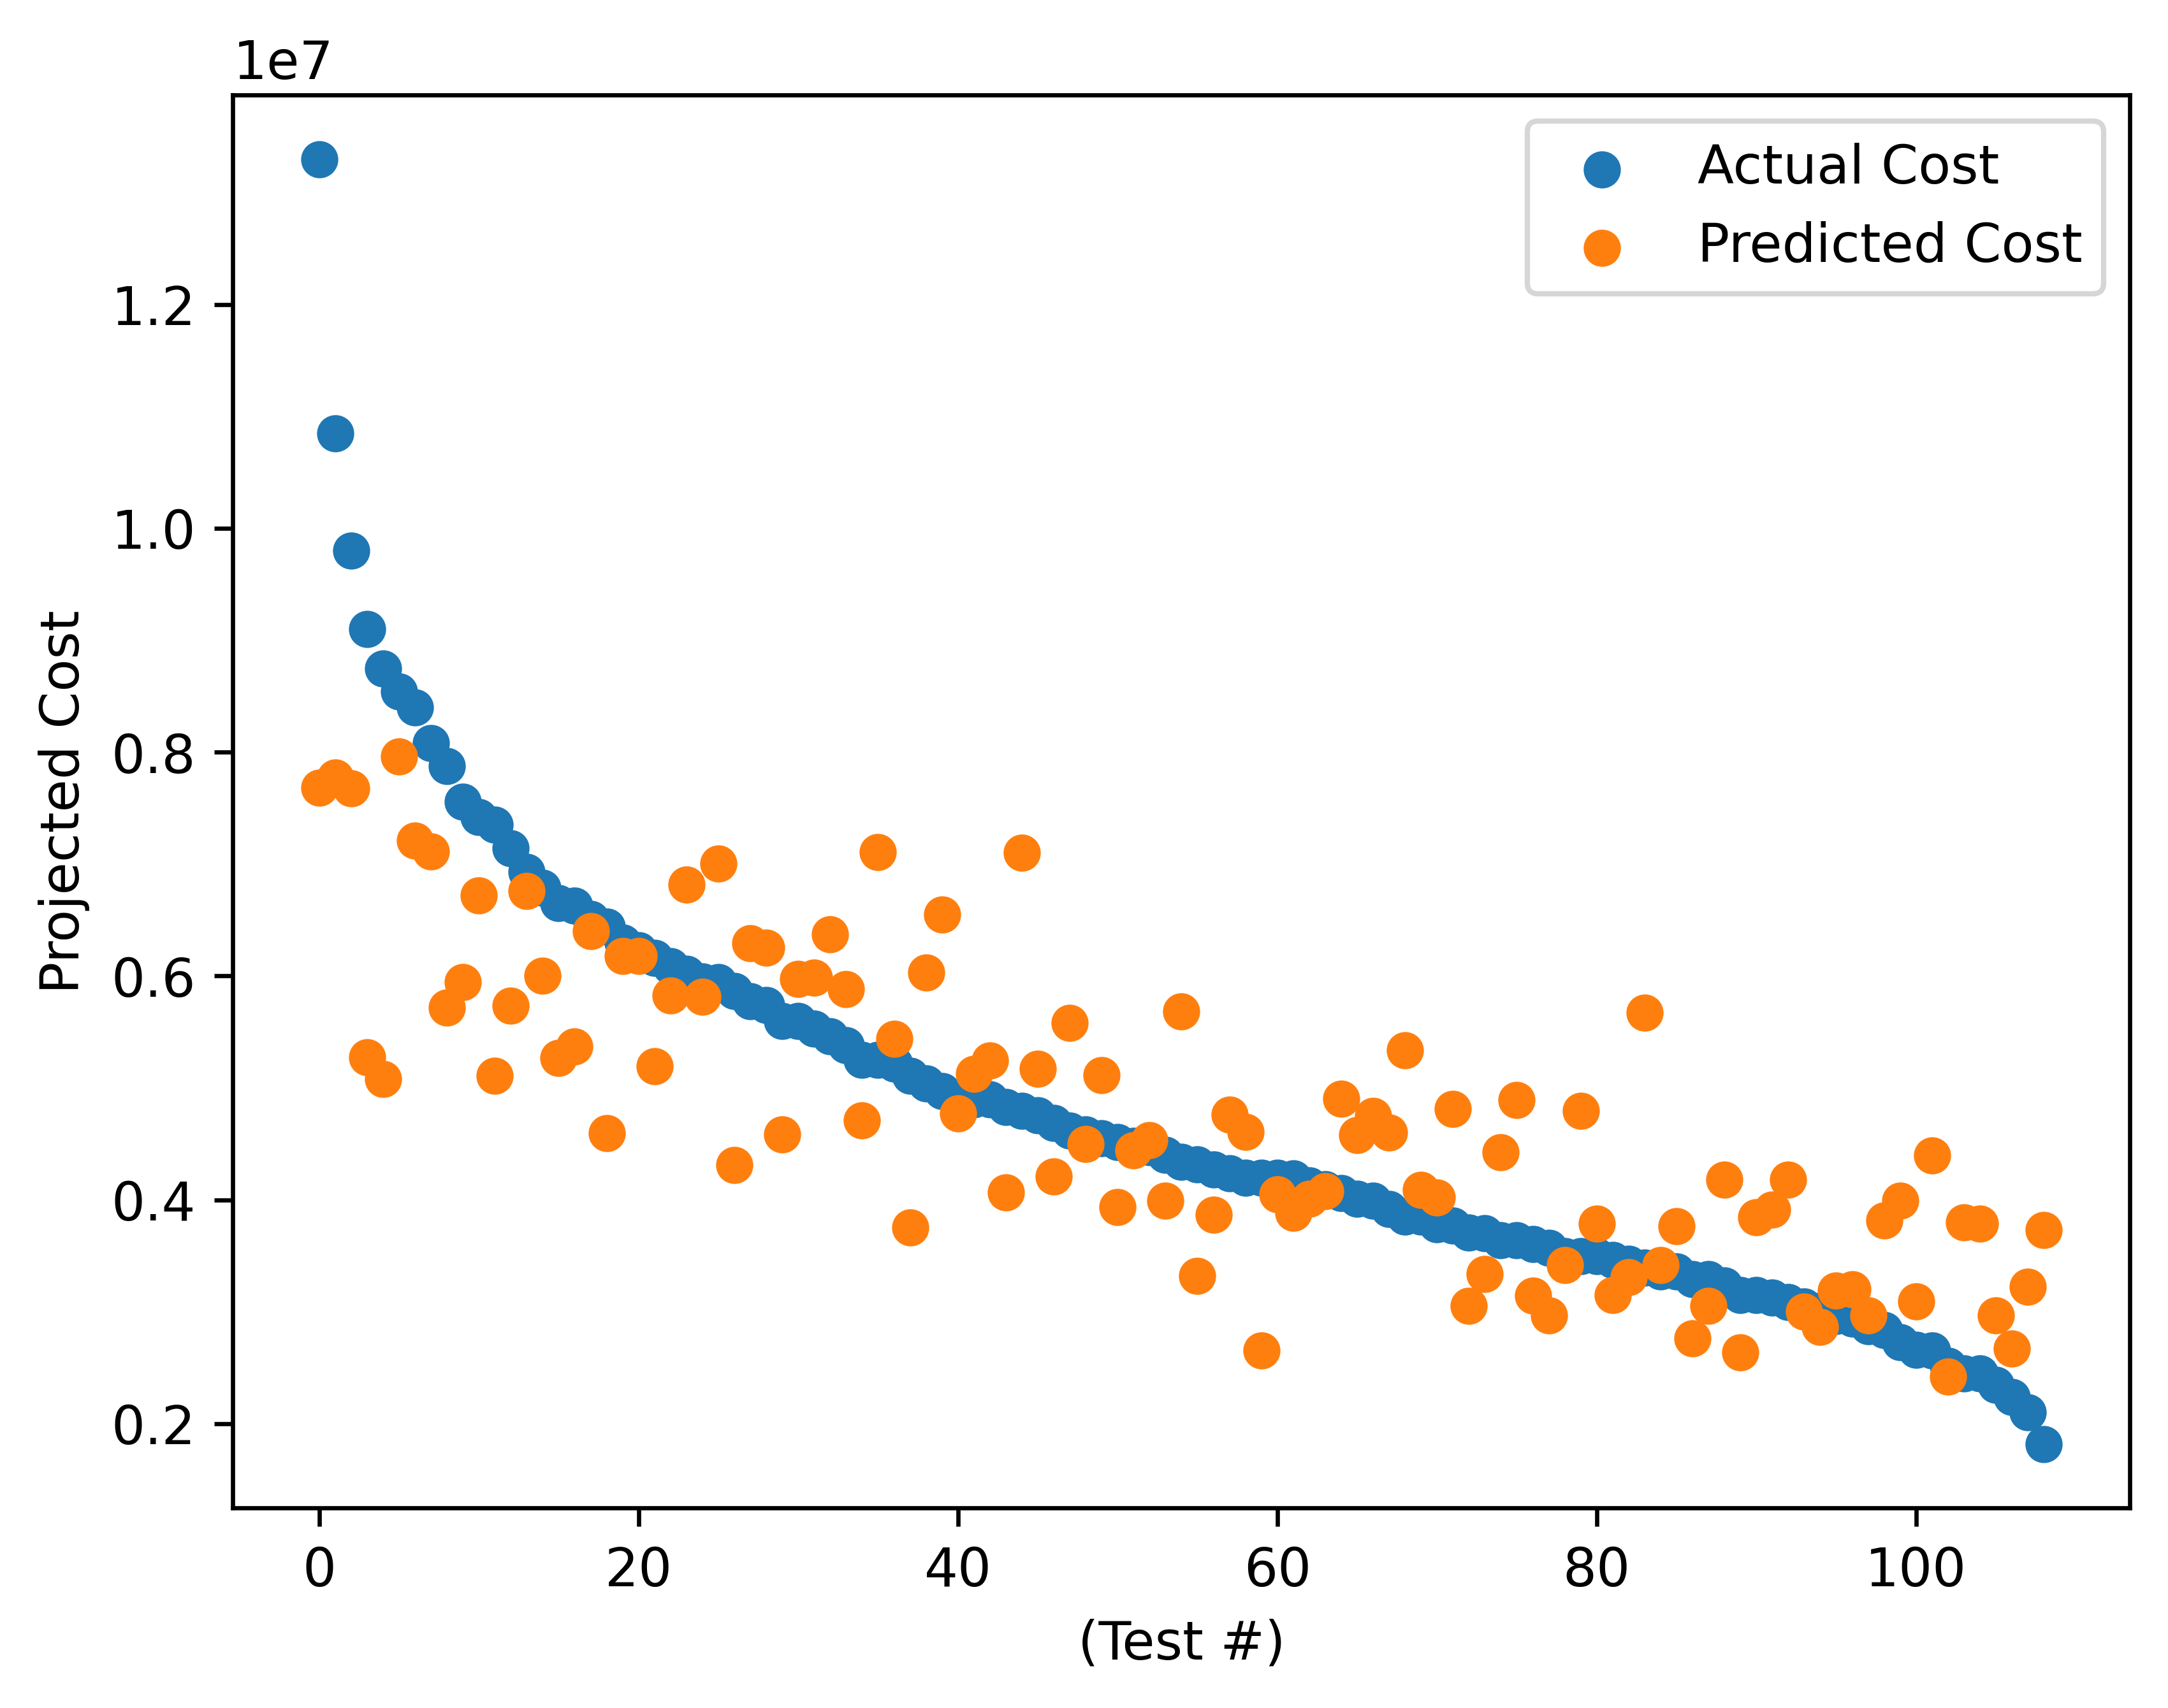

Validation Loss:  756907700000.0
Parameters: 
193.927643x1 + 283982.375000x2 + 795494.875000x3 + 355346.781250x4 + 552604.937500x5 + 490475.500000x6 + 266848.812500x7 + 592473.562500x8 + 733870.187500x9 + 315476.218750x10 + 500930.156250x11 + 1462.314209
Epoch 50, Loss 0.969877
Epoch 100, Loss 0.940531
Epoch 150, Loss 0.912527
Epoch 200, Loss 0.885804
Epoch 250, Loss 0.860301
Epoch 300, Loss 0.835964
Epoch 350, Loss 0.812738
Epoch 400, Loss 0.790572
Epoch 450, Loss 0.769418
Epoch 500, Loss 0.749229


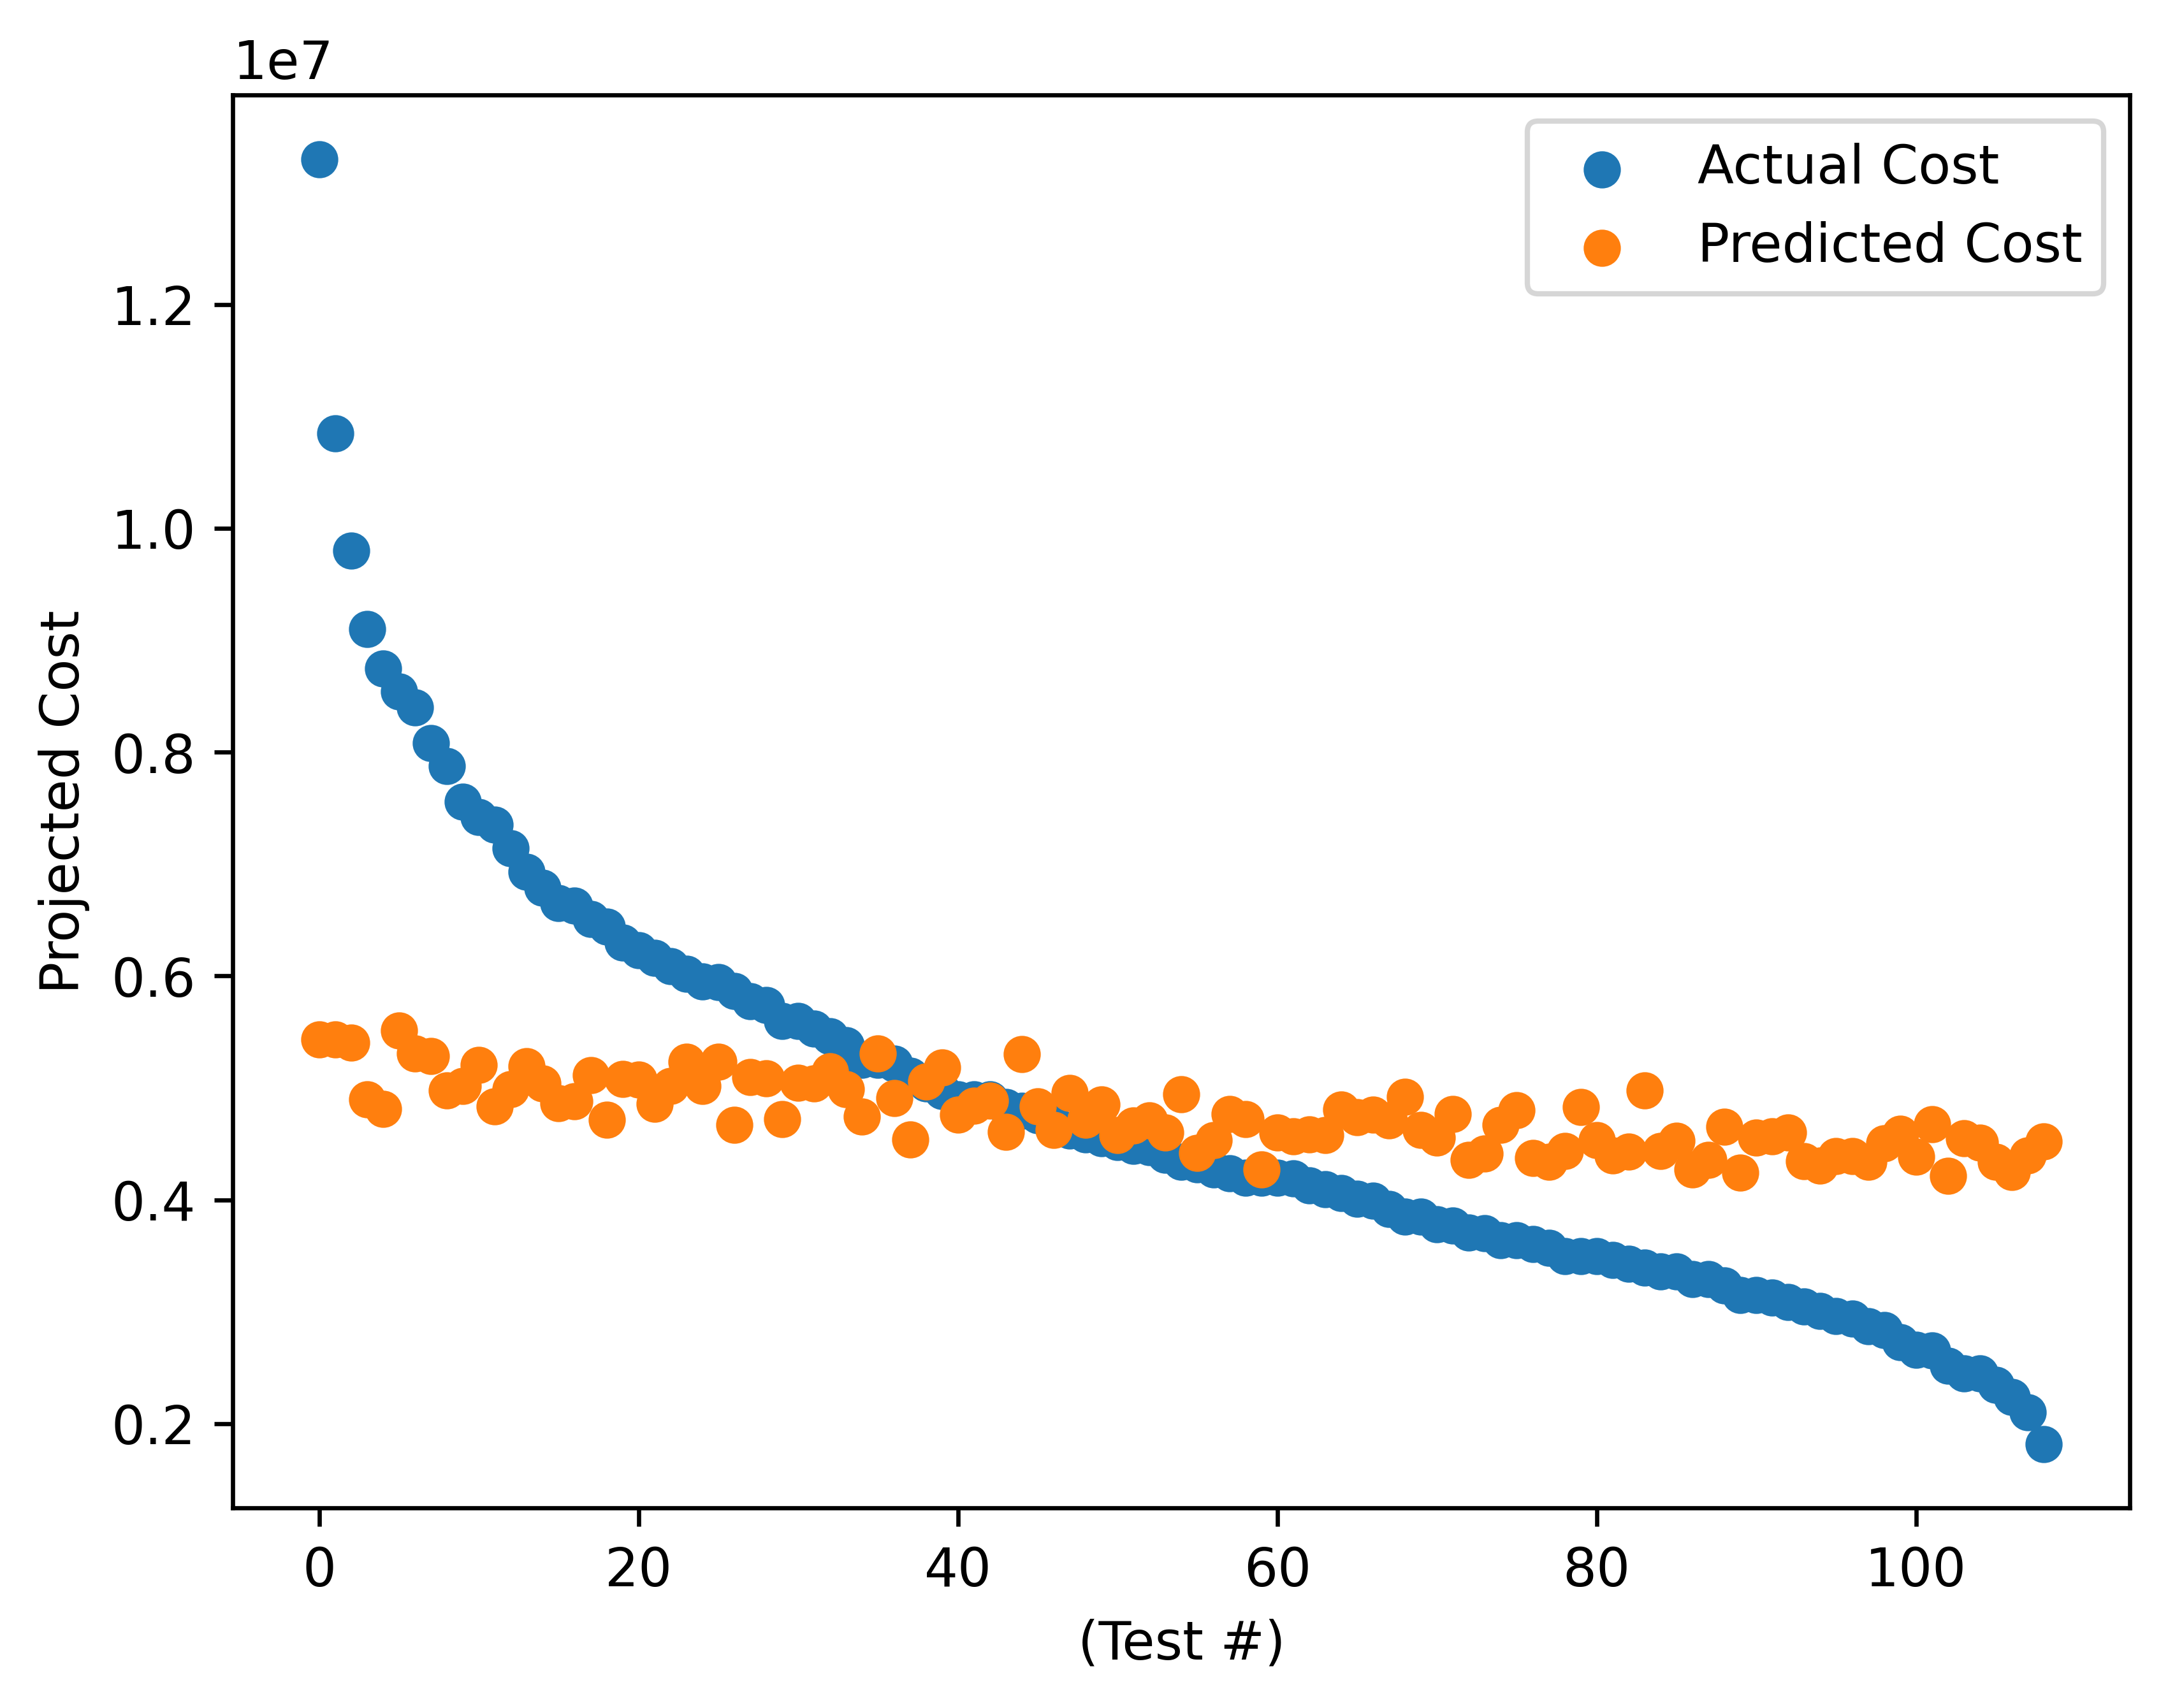

Validation Loss:  1469964900000.0
Parameters: 
41.031509x1 + 81906.625000x2 + 174796.468750x3 + 81860.148438x4 + 141406.390625x5 + 121680.437500x6 + 61868.312500x7 + 100049.398438x8 + 161491.953125x9 + 74348.687500x10 + 119789.906250x11 + 3628255.250000


In [5]:
import torch as pt
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import StandardScaler

filepath = "/content/Housing.csv"

df = pd.read_csv(filepath)

scaler_X = StandardScaler() # Scaler for input features
scaler_XV = StandardScaler() # Scaler for validation input features
scaler_y = StandardScaler() # Scaler for target variable

t_u = df.values[:, 1:12]
t_c = df.values[:, 0].astype(np.float32)

for i in range(len(t_u)):
  for j in range(len(t_u[0])):
    if t_u[i][j] == "yes":
      t_u[i][j] = 1
    elif t_u[i][j] == "no":
      t_u[i][j] = 0
for i in range(len(t_u[11])):
  if t_u[11][i] == "furnished":
    t_u[i][j] = 2
  elif t_u[11][i] == "semi-furnished":
    t_u[i][j] = 1
  elif t_u[11][i] == "unfurnished":
    t_u[i][j] = 0

t_u = t_u.astype(np.float32)

t_o = t_u.copy()
t_o = t_o.T

validation_indices = np.arange(0, len(t_u), 5)

t_uv = t_u[validation_indices]
t_u = np.delete(t_u, validation_indices, axis=0)

t_u = scaler_X.fit_transform(t_u) # Fit and transform input features
t_uv = scaler_XV.fit_transform(t_uv)

t_cv = t_c[validation_indices]
t_c = np.delete(t_c, validation_indices)

t_c = scaler_y.fit_transform(t_c.reshape(-1, 1)).reshape(-1) # Fit and transform target variable

t_c = pt.from_numpy(t_c)
t_u = pt.from_numpy(t_u)
t_uv = pt.from_numpy(t_uv)

def model(t_u, params):
  return t_u @ params[:-1] + params[-1]


def loss_fn(t_p, t_c):
  squared_diffs = (t_p-t_c)**2
  return squared_diffs.mean()

def loss_numpy(res, y):
  for i in range(len(res)):
    res[i] = np.float64(res[i])
  for i in range(len(y)):
    y[i] = np.float64(y[i])
  return np.sum((res - y) ** 2) / (2 * len(res))

def training_loop(n_epochs, optimizer, params, t_u, t_c, method="linear"):
  for epoch in range(1, n_epochs + 1):
    t_p = model(t_u, params)
    loss = loss_fn(t_p, t_c)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 50 == 0:
      print('Epoch %d, Loss %f' % (epoch, float(loss)))
  return params
def train_with_method(t_u, t_c, lr=0.01):
  params = np.zeros(len(t_u[0])+1).astype(np.float32)
  params = pt.tensor(params, requires_grad=True)
  optimizer = pt.optim.SGD([params], lr=lr)
  results = training_loop(
      n_epochs = 500,
      optimizer = optimizer,
      params = params,
      t_u = t_u,
      t_c = t_c
  )
  return results
def train(t_u, t_c, lr=0.01):
  # Training
  params = train_with_method(t_u, t_c, lr)

  # Postprocessing
  t_p = model(t_uv, params)
  t_p = t_p.detach().numpy()
  t_co = scaler_y.inverse_transform(t_c.reshape(-1, 1)).reshape(-1)
  t_p = scaler_y.inverse_transform(t_p.reshape(-1, 1)).reshape(-1)
  cf = loss_numpy(t_p, t_cv)
  t_c = t_co

  params = params.detach().numpy()

  params[:-1] = (scaler_y.scale_ * params[:-1]) / scaler_X.scale_
  sum_term = np.sum((params[:-1] * scaler_X.mean_) / scaler_y.scale_.item())
  params[-1] = scaler_y.scale_.item() * params[-1] - scaler_y.scale_.item() * sum_term + scaler_y.mean_.item()

  # Display
  fig = plt.figure(dpi=600)
  plt.xlabel("(Test #)")
  plt.ylabel("Projected Cost")
  plt.scatter(np.arange(len(t_uv)), t_cv, label="Actual Cost")
  plt.scatter(np.arange(len(t_uv)), t_p, label="Predicted Cost")
  plt.legend()
  plt.show()
  print("Validation Loss: ", cf)
  print(f"Parameters: ")
  for i in range (len(params) - 1):
    print(f"{params[i]:.6f}x{i+1} +", end = " ")
  print(f"{params[len(params) - 1]:.6f}")
train(t_u, t_c, lr=0.1)
train(t_u, t_c)
train(t_u, t_c, lr=0.001)
train(t_u, t_c, lr=0.0001)